# 🔍 **EDA Кейс: Анализ оттока клиентов (Telco Customer Churn)**

**Датасет:** Telco Customer Churn (Kaggle)  
**Исследовательский вопрос:** «Какие клиенты склонны уходить и какие факторы связаны с оттоком клиентов?»  

---

# **Часть 1. Бизнес-контекст, цели проекта и задачи исследования**

## **1.1 Бизнес-контекст и верхнеуровневые цели**

**Ключевой вопрос исследования:** Какие клиенты склонны уходить и какие факторы сильнее всего связаны с оттоком?

**Бизнес-кейс:**  
Телекоммуникационная компания стремится снизить отток абонентов и сохранить клиентскую базу. Уход клиентов приводит к потере регулярной выручки и увеличивает затраты компании на привлечение новых абонентов. Компании необходимо заранее выявлять клиентов с повышенным риском ухода и понимать, какие характеристики связаны с оттоком.  

**Бизнес-задача:**  
Определить ключевые факторы, связанные с оттоком абонентов, и выделить клиентов с повышенным риском ухода для проведения мероприятий по их удержанию.

**Цель проекта:**  
Провести анализ данных об абонентах телекоммуникационной компании, подготовить признаки и разработать модель машинного обучения для прогнозирования оттока, а также выявить ключевые факторы, связанные с уходом клиентов.  
Качество модели будет оцениваться с точки зрения ее способности максимально полно выявлять абонентов, склонных к уходу.


### Датасет Telco Customer Churn
Датасет содержит информацию об абонентах телекоммуникационной компании, их демографических характеристиках, подключённых услугах, условиях контрактов и платежах.  
**Размер датасета:** 7 043 записи, 21 столбец.  
**Единица наблюдения:** один абонент телекоммуникационной компании.  
**Целевой признак :**  `Churn` - факт оттока абонента:

- Yes - абонент ушёл;
- No - абонент остался.

**Тип задачи машинного обучения:**  бинарная классификация.  


## **1.2 Цели и задачи этапа EDA (Разведочного анализа)**

**Цель EDA:** изучить структуру, качество и особенности данных, выявить закономерности и взаимосвязи, которые могут быть связаны с оттоком абонентов, и определить особенности данных, которые необходимо учесть при построении модели машинного обучения.  
**Задачи EDA:**
1. Изучить структуру датасета, состав и типы признаков.

2. Оценить качество данных: выявить пропуски, дубликаты, некорректные и аномальные значения.

3. Исследовать распределение признаков и целевого показателя Churn, оценить соотношение ушедших и оставшихся клиентов.

4. Выявить взаимосвязи между характеристиками абонентов и оттоком.

5. Сравнить характеристики ушедших и оставшихся клиентов, определить наиболее заметные различия между группами.

6. Проверить стартовые бизнес-гипотезы о факторах оттока.

7. Сформулировать выводы и определить необходимые действия по подготовке данных к построению модели машинного обучения.






## **1.3 Стартовые бизнес-гипотезы**


*   Клиенты с помесячными контрактами уходят чаще
*   Высокие ежемесячные платежи связаны с вероятность оттока
*   Способ оплаты связан с вероятностью оттока
*   Наличие услуг техподдержки снижает вероятность ухода клиента





# 1. Импорты и настройки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from math import pi
from scipy.stats import chi2_contingency
import kagglehub




from kagglehub import KaggleDatasetAdapter
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_predict, learning_curve
)
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    roc_curve, precision_recall_curve
)
from matplotlib.colors import LinearSegmentedColormap
from phik.report import plot_correlation_matrix

c:\Users\Дарино4ка\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 2. Загрузка данных

In [2]:
file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df_before_substitute = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "blastchar/telco-customer-churn",
    file_name
)


# 3. Первичный осмотр данных

## 3.1. Первый взгляд на данные

In [3]:
df_before_substitute.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df_before_substitute.sample(5, random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


## 3.2. Технический паспорт данных

In [5]:
df_before_substitute.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Анализ .info()

---


| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(1), int64(2), object(18) | TotalCharges типа object -> надо проверить пропуски |



## 3.3. Статистическая сводка

In [6]:
df_before_substitute.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [7]:
df_before_substitute.describe(include=['object', 'category']).T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


# Качество данных

## 4.1. Пропуски

In [8]:
# Анализ пустых ячеек

missing_count = df_before_substitute.isna().sum()
missing_pct = (df_before_substitute.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%


In [9]:
empty_count = (df_before_substitute['TotalCharges'] == (' ')).sum()
print(f"Количество ячеек с пустой строкой: {empty_count}")

Количество ячеек с пустой строкой: 11


In [10]:
df_before_substitute[df_before_substitute['TotalCharges'] == (' ')]['tenure'].unique()

array([0])

**Вывод**: Видим, что все объекты, по которым были пропуски в поле `TotalCharges`, имеют нули в `Tenure` -> это новые абоненты, которые еще не платили. Можем заполнить нулями.

In [11]:
df = df_before_substitute.copy()

df['TotalCharges'] = df['TotalCharges'].replace(' ', 0).astype('float')

При анализе уникальных значений категориальных признаков обнаружено, что в некоторых столбцах, где ожидаются значения Yes/No, присутствует третья категория.
Проверим, какие именно значения встречаются в этих столбцах.

In [12]:
сols_to_check = [
    'MultipleLines', 
    'OnlineSecurity', 
    'OnlineBackup', 
    'DeviceProtection', 
    'TechSupport', 
    'StreamingTV',
    'StreamingMovies'
]

for col in сols_to_check:
    print(df[col].value_counts(dropna=False))
    print()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64



В результате проверки установлено, что:  
    в поле `MultipleLines` наряду со значениями 'Yes' и 'No' присутствует категория 'No phone service';  
    в полях `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV` и `StreamingMovies` присутствует категория 'No internet service'.

Эти значения отражают отсутствие соответствующей услуги.
На этапе EDA сохраняем исходные категории, поскольку они содержат дополнительную информацию о подключенных услугах абонента. При подготовке данных к моделированию рассмотрим возможность объединения этих категорий со значением 'No'.

## 4.3. Дубли

In [13]:
# Дубликаты по customerID
customer_duplicates = df.duplicated(subset=['customerID']).sum()
print(f" Дубликатов customerID: {customer_duplicates:,} ({customer_duplicates/len(df)*100:.2f}%)")

 Дубликатов customerID: 0 (0.00%)


## 4.4. Аномалии

In [14]:
# Есть ли MonthlyCharges с нулевым значением?

zero_MonthlyCharges = df[df['MonthlyCharges'] == 0]
print(f" Нулевых значений месячной оплаты: {len(zero_MonthlyCharges)}")

if len(zero_MonthlyCharges) > 0:
    print("\nПримеры:")
    display(zero_MonthlyCharges)

 Нулевых значений месячной оплаты: 0


## 4.5. Анализ выбросов

Визуальный метод: **boxplot**

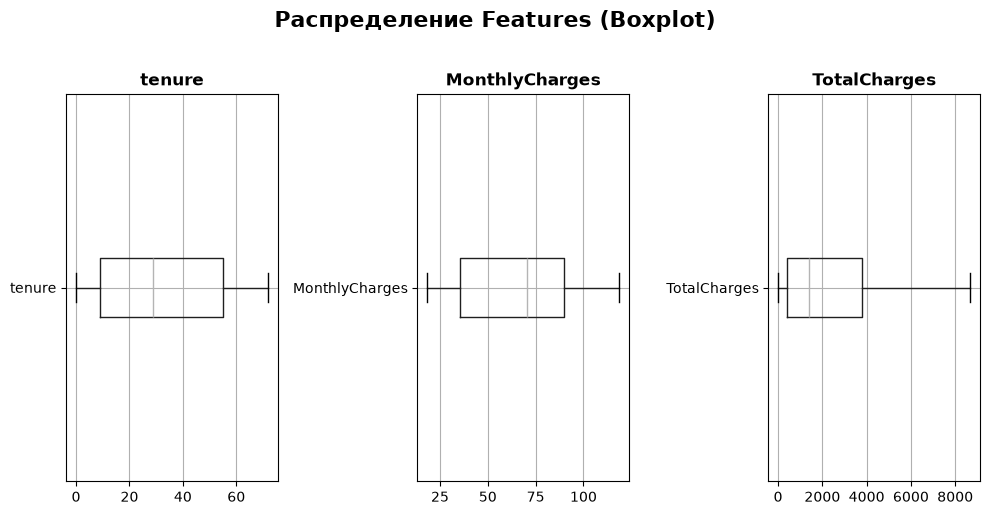

In [15]:
# features для анализа выбросов
features = ['tenure','MonthlyCharges','TotalCharges']

# Преобразование TotalCharges в числовой тип
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Boxplot для features
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes = axes.flatten()

for idx, col in enumerate(features):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение Features (Boxplot)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Анализ выбросов:**

| Признак | Выбросы | 
|---------|---------|
| **tenure** | Отсутствуют | 
| **MonthlyCharges** | Отсутствуют |
| **TotalCharges** | Отсутствуют |

In [16]:
# Соотношение количества услуг и ежемесячного платежа.
# Гипотеза: если подключенных услуг много, а ежемесячный платеж маленький, то клиент уже был удержан.

services = [ 'PhoneService',
            'MultipleLines',
             'InternetService',
             'OnlineSecurity',
             'OnlineBackup',
             'DeviceProtection',
             'TechSupport',
             'StreamingTV',
             'StreamingMovies'
             ]

df_temp = df.copy()

for col in services:
  if col == 'InternetService':
    df_temp[col] = df_temp[col].apply(lambda x: 0 if x == 'No' else 1)
  else:
    df_temp[col] = df_temp[col].apply(lambda x: 1 if x == 'Yes' else 0)

df_temp['NumServices'] = df_temp[services].sum(axis=1)

df_temp['PricePerService'] = df_temp['MonthlyCharges'] / df_temp['NumServices']

print(df_temp[[ 'MonthlyCharges',
          'NumServices',
           'PricePerService',
           'PhoneService',
           'InternetService',
           'StreamingTV' ]].head())

low_price_clients = df_temp.query("PricePerService < 10")
high_price_clients = df_temp.query("PricePerService > 40")

print("\nКлиенты с очень низкой ценой за услугу (<$10):")
print(low_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])
print("\nКлиенты с очень высокой ценой за услугу (>$40):")
print(high_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])

   MonthlyCharges  NumServices  PricePerService  PhoneService  \
0           29.85            2          14.9250             0   
1           56.95            4          14.2375             1   
2           53.85            4          13.4625             1   
3           42.30            4          10.5750             0   
4           70.70            2          35.3500             1   

   InternetService  StreamingTV  
0                1            0  
1                1            0  
2                1            0  
3                1            0  
4                1            0  

Клиенты с очень низкой ценой за услугу (<$10):
      customerID  MonthlyCharges  NumServices  PricePerService
43    4671-VJLCL           79.85            8         9.981250
131   6207-WIOLX           58.60            6         9.766667
140   3146-MSEGF           88.05            9         9.783333
167   5997-OPVFA           89.05            9         9.894444
206   6348-SNFUS           55.45          

# Одномерный анализ

### 5.1 Целевая переменная Churn

Сначала оцениваем доли ушедших и оставшихся клиентов. В исходных данных 5174 клиента не ушли, значит отток составляет около 26,5% (1869 из 7043). Классы умеренно несбалансированы: при построении модели accuracy сама по себе будет недостаточной метрикой.

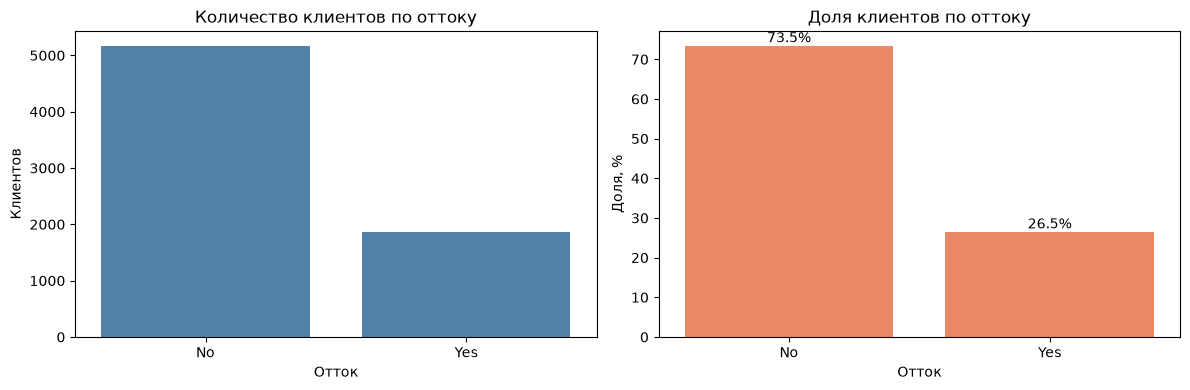

In [17]:
df_eda = df.copy(deep=True)

df_eda["ChurnFlag"] = df_eda["Churn"].map({"No": 0, "Yes": 1})
if df_eda["ChurnFlag"].isna().any():
    raise ValueError("В Churn обнаружены неизвестные категории")

churn_share = (
    df_eda["Churn"].value_counts(normalize=True)
    .reindex(["No", "Yes"], fill_value=0).mul(100)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_eda, x="Churn", order=["No", "Yes"],
              ax=axes[0], color="steelblue")
axes[0].set(title="Количество клиентов по оттоку", xlabel="Отток", ylabel="Клиентов")
sns.barplot(x=churn_share.index, y=churn_share.values, order=["No", "Yes"],
            ax=axes[1], color="coral")
axes[1].set(title="Доля клиентов по оттоку", xlabel="Отток", ylabel="Доля, %")
for bar in axes[1].patches:
    axes[1].annotate(f"{bar.get_height():.1f}%",
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha="center", va="bottom")
plt.tight_layout()
plt.show()


**Вывод:** в датасете 1 869 абонентов (26,5%) прекратили обслуживание, 5 174 (73,5%) остались клиентами компании. Таким образом, отток затрагивает примерно каждого четвёртого абонента.  
Классы представлены неравномерно, поэтому при дальнейшем анализе будем сравнивать долю ушедших клиентов внутри сегментов, а не только абсолютное количество. Это также необходимо учитывать при выборе метрик качества модели.

### 5.2 Числовые признаки

`tenure` — срок обслуживания в месяцах, `MonthlyCharges` — ежемесячный платёж, `TotalCharges` — накопленные платежи. `MonthlyChargesChange` рассчитан как `TotalCharges - MonthlyCharges × tenure`; он показывает разницу между фактическими накопленными платежами и оценкой при неизменной месячной цене. Для каждого показателя смотрим форму распределения, медиану и возможные крайние значения.

In [18]:
services_yes_no = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 
    'StreamingTV', 'StreamingMovies'
]
num_yes = (df_eda[services_yes_no] == 'Yes').sum(axis=1)

# 4. Отдельно обрабатываем интернет (если это не 'No', значит услуга есть)
num_internet = (df_eda['InternetService'] != 'No').astype(int)

# 5. Складываем
df_eda['NumServices'] = num_yes + num_internet

df_eda["MonthlyChargesChange"] = (
    df_eda["TotalCharges"] - df_eda["MonthlyCharges"] * df_eda["tenure"]
)

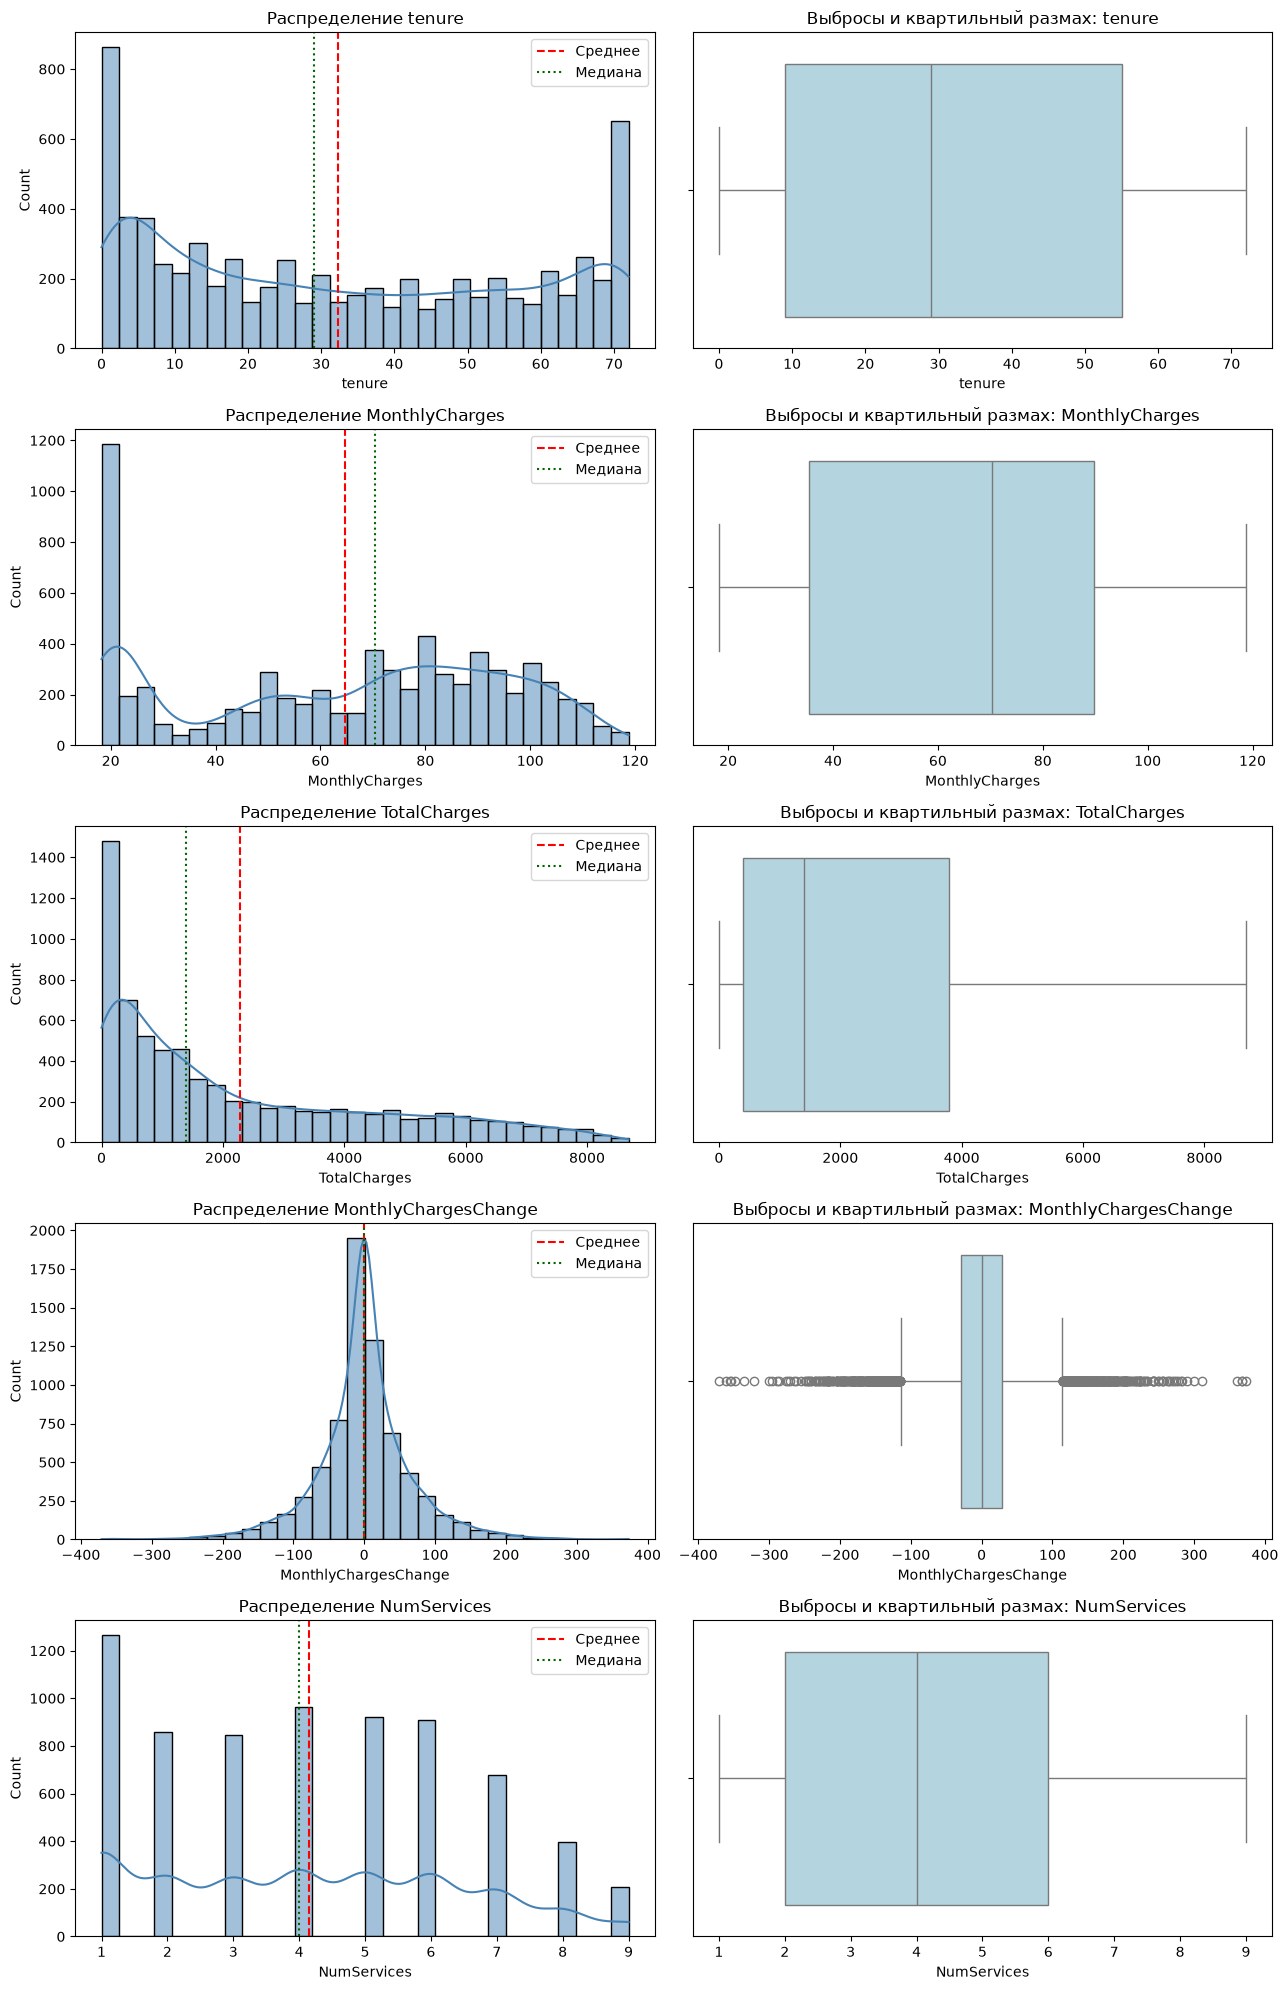

In [19]:
numeric_features = [
    'tenure', 'MonthlyCharges', 'TotalCharges', 'MonthlyChargesChange', 'NumServices'
]

fig, axes = plt.subplots(len(numeric_features), 2, figsize=(13, 4 * len(numeric_features)))
for row, col in enumerate(numeric_features):
    sns.histplot(df_eda[col].dropna(), bins=30, kde=True, ax=axes[row, 0], color='steelblue')
    axes[row, 0].axvline(df_eda[col].mean(), color='red', linestyle='--', label='Среднее')
    axes[row, 0].axvline(df_eda[col].median(), color='darkgreen', linestyle=':', label='Медиана')
    axes[row, 0].set(title=f'Распределение {col}', xlabel=col)
    axes[row, 0].legend()
    sns.boxplot(x=df_eda[col], ax=axes[row, 1], color='lightblue')
    axes[row, 1].set(title=f'Выбросы и квартильный размах: {col}', xlabel=col)
plt.tight_layout()
plt.show()

**Выводы по распределению числовых признаков:**  
`tenure` имеет неоднородное распределение: наблюдается заметная концентрация абонентов с небольшим сроком обслуживания, а также клиентов с длительным сроком пользования услугами.  
`MonthlyCharges` распределён неравномерно: присутствует группа абонентов с низкими ежемесячными платежами и более широкая группа со средними и высокими значениями.  
`TotalCharges` имеет выраженный правый хвост. Значения показателя связаны со сроком обслуживания и размером ежемесячных платежей.  
`MonthlyChargesChange` в основном сосредоточен около нуля, но имеет отклонения в обе стороны. Это может отражать изменение стоимости услуг в течение периода обслуживания, однако требует дополнительной проверки.  
Крайние значения числовых признаков не удаляем автоматически: они могут отражать реальные особенности обслуживания абонентов. Необходимость дополнительной обработки будем оценивать с учётом результатов моделирования.

### 5.3 Категориальные признаки

Для каждого категориального признака считаем долю оттока внутри категории. Графики по всем признакам собраны в сетку 4 × 4, чтобы можно было сравнить картину целиком.

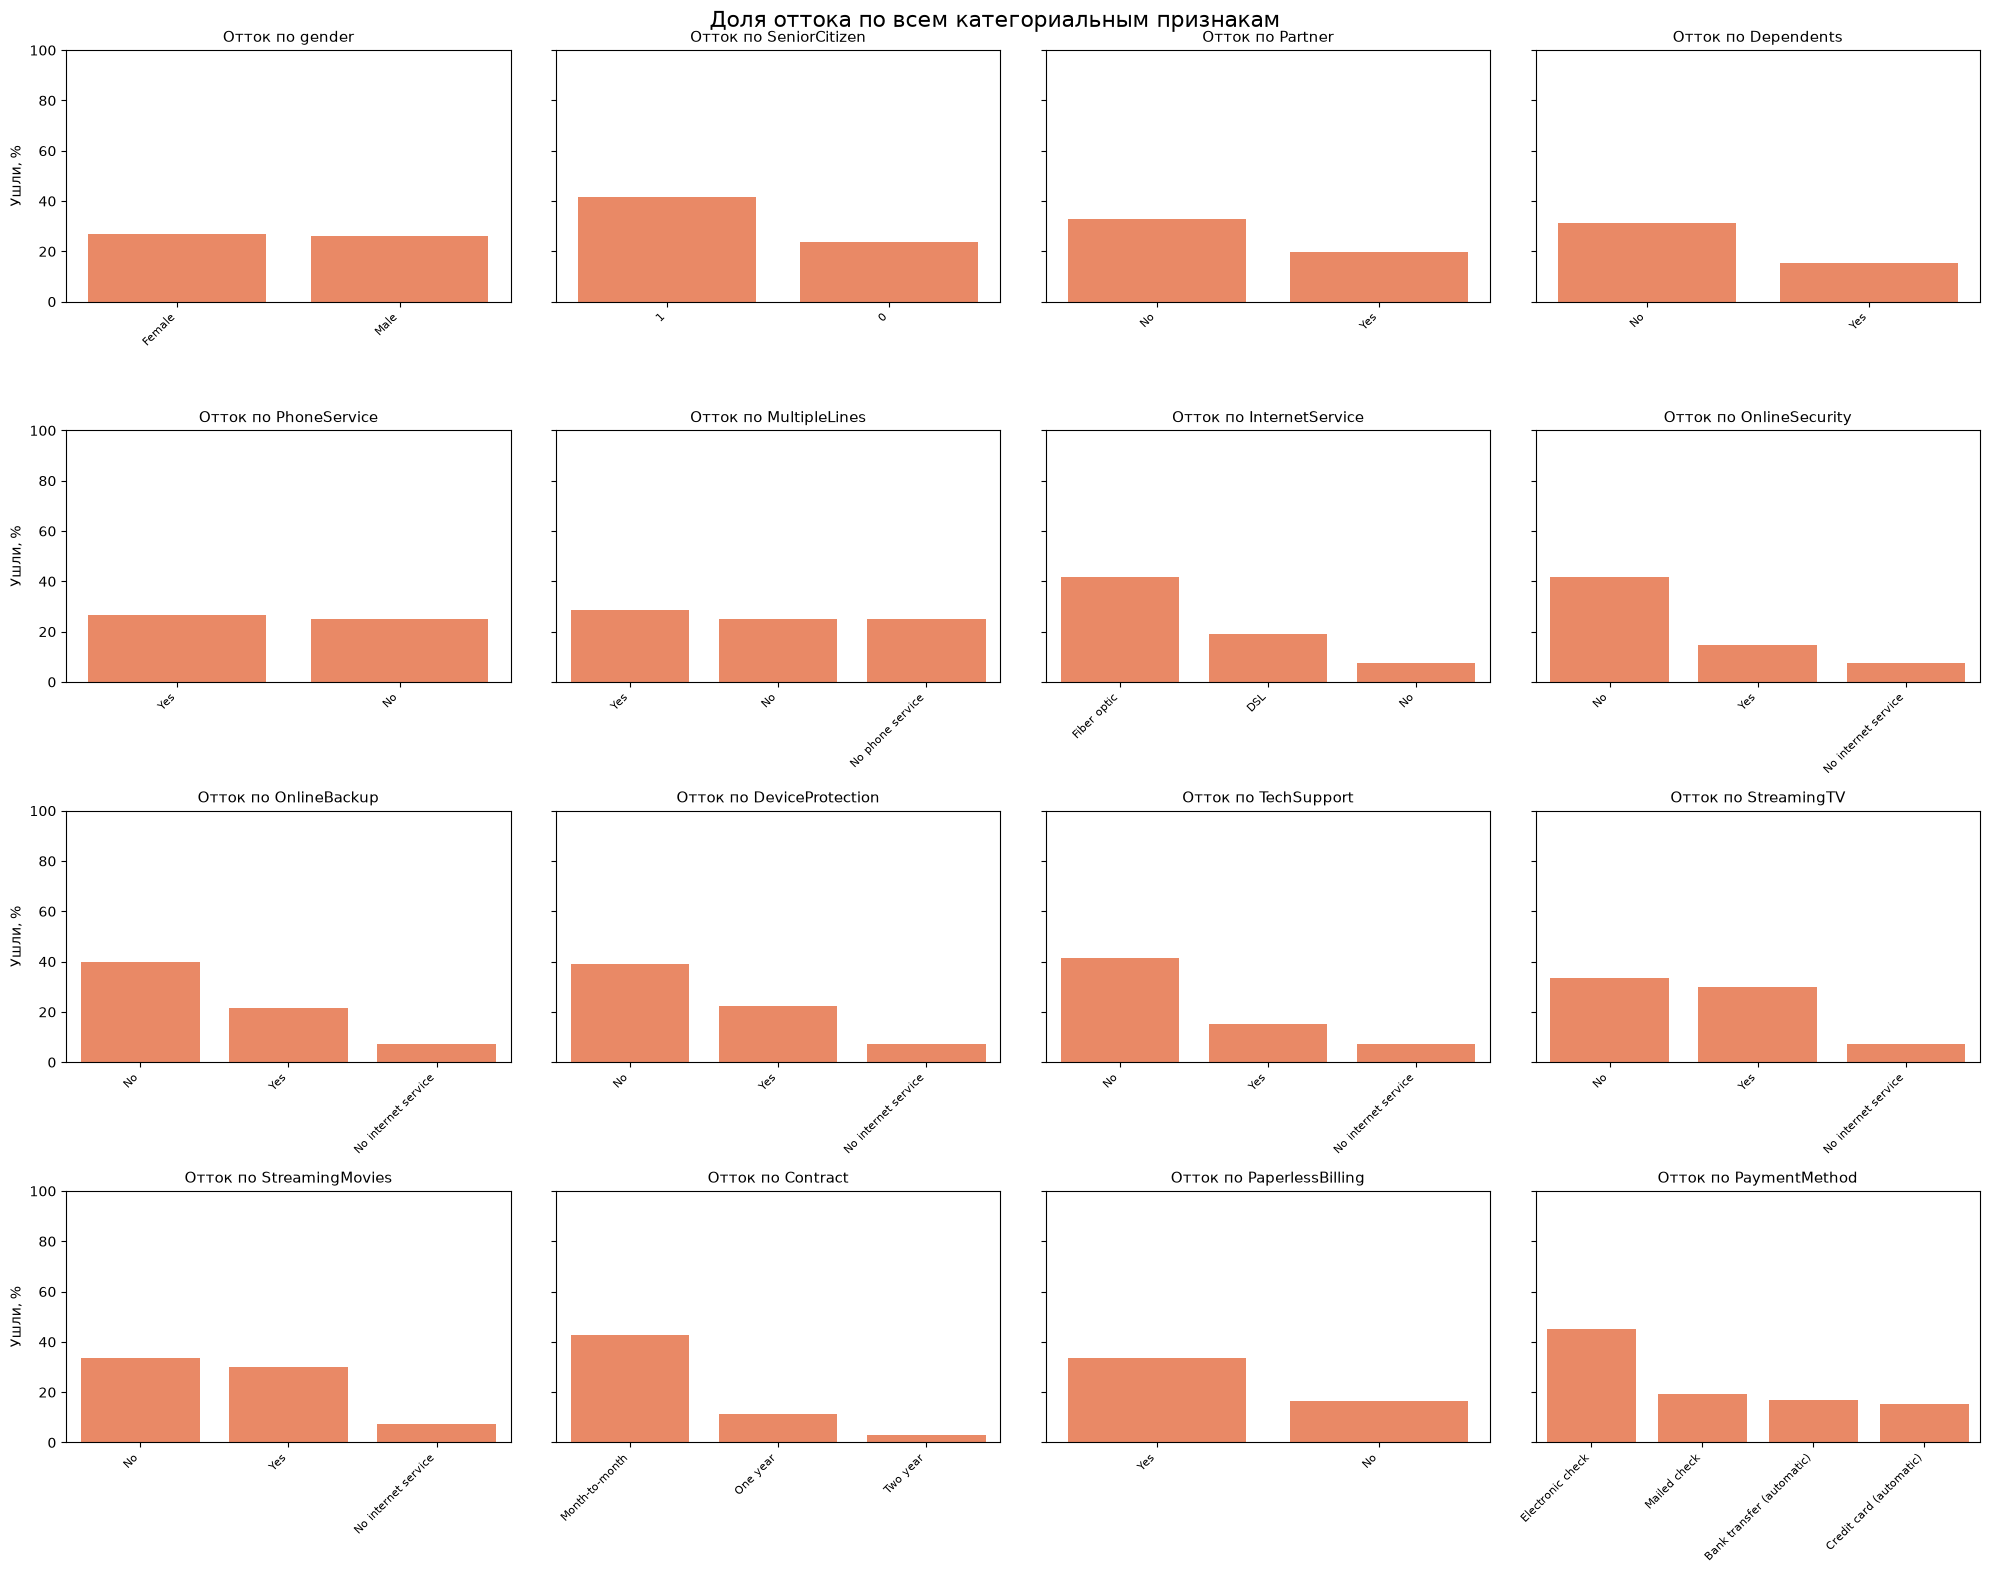

In [20]:
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16), sharey=True)
for ax, col in zip(axes.flat, categorical_features):
    rates = (df_eda.groupby(col, observed=False)['ChurnFlag']
             .mean().mul(100).dropna().sort_values(ascending=False))
    sns.barplot(x=rates.index.astype(str), y=rates.values,
                ax=ax, color='coral')
    ax.set_title(f'Отток по {col}', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Ушли, %' if ax in axes[:, 0] else '')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_ha('right')
fig.suptitle('Доля оттока по всем категориальным признакам', fontsize=16)
plt.tight_layout()
plt.show()


**Выводы по категориальным признакам:**
Наиболее заметные различия в доле оттока наблюдаются в зависимости от типа договора и способа оплаты. Наибольшая доля ушедших клиентов приходится на абонентов с помесячным договором (около 43%) и оплатой электронным чеком (около 45%).  
Также повышенная доля оттока наблюдается среди пожилых клиентов, абонентов без партнёра и иждивенцев, а также клиентов, использующих безбумажный документооборот.  
Среди пользователей интернет-услуг более высокая доля оттока наблюдается у клиентов с оптоволоконным подключением (около 42%). Для клиентов, не подключивших онлайн-защиту, резервное копирование, защиту устройств и техническую поддержку, доля оттока также выше, чем для пользователей этих услуг.  
Для стриминговых услуг, наличия телефонной связи и нескольких телефонных линий различия в доле оттока выражены слабо. По признаку пола существенных различий не наблюдается.  
Полученные результаты показывают наличие взаимосвязей между характеристиками абонентов и оттоком, но не доказывают причинно-следственную зависимость и требуют дальнейшего исследования.  


# Многомерный анализ

## 6.1 Связи числовых признаков и оттока

Сравниваем распределения числовых показателей между ушедшими и оставшимися клиентами. Корреляция Спирмена полезна как оценка монотонных связей и менее чувствительна к форме распределения, чем обычная линейная корреляция Пирсона.

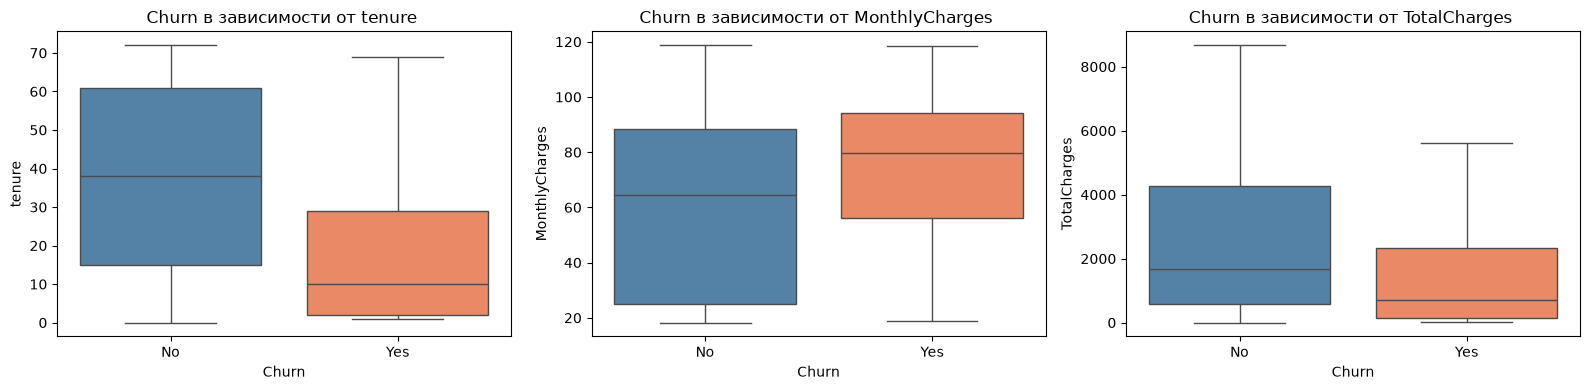

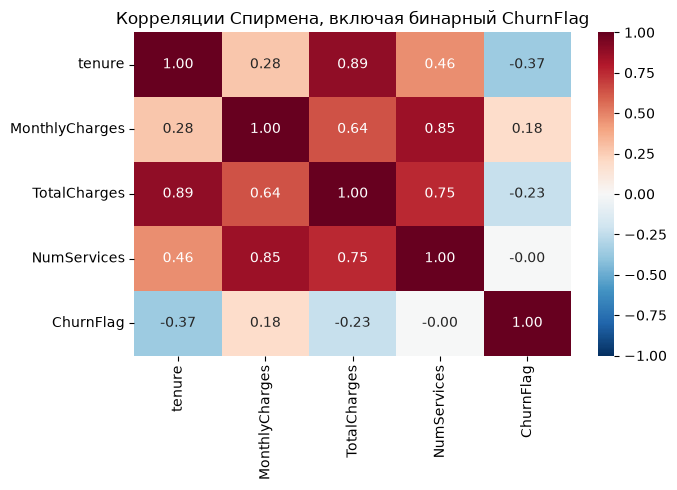

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df_eda, x='Churn', y=col,
                order=['No', 'Yes'], hue='Churn', hue_order=['No', 'Yes'],
                ax=ax, showfliers=False,
                palette={'No': 'steelblue', 'Yes': 'coral'},
                legend=False)
    ax.set_title(f'Churn в зависимости от {col} ')
plt.tight_layout()
plt.show()

spearman = df_eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'ChurnFlag']].corr(method='spearman')
plt.figure(figsize=(7, 5))
sns.heatmap(spearman, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Корреляции Спирмена, включая бинарный ChurnFlag')
plt.tight_layout()
plt.show()

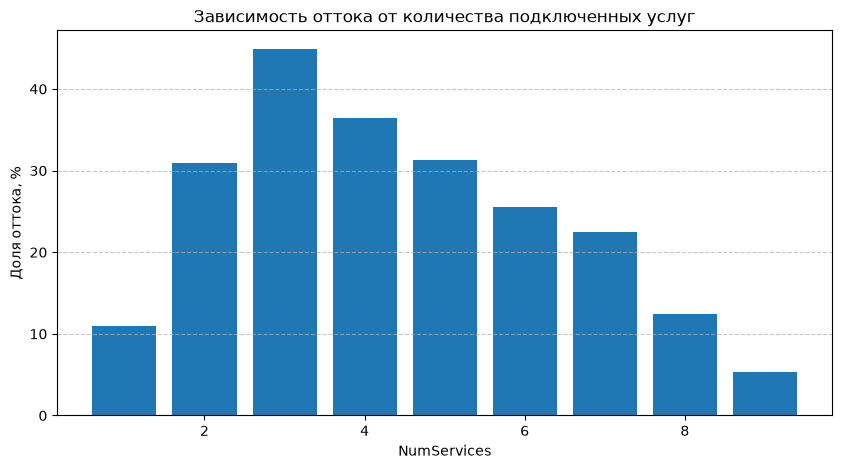

In [22]:
churn_by_services = df_eda.groupby('NumServices')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).reset_index()

plt.figure(figsize=(10, 5))
plt.bar(churn_by_services['NumServices'], churn_by_services['Churn'])
plt.title('Зависимость оттока от количества подключенных услуг')
plt.xlabel('NumServices')
plt.ylabel('Доля оттока, %')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Выводы:**
Наиболее заметное различие между ушедшими и оставшимися клиентами наблюдается по сроку обслуживания (`tenure`). Медианный срок обслуживания ушедших абонентов составляет около 10 месяцев, оставшихся — около 38 месяцев. Корреляция Спирмена с целевым признаком составляет −0,37.  
У ушедших клиентов также наблюдаются более высокие ежемесячные платежи (`MonthlyCharges`): медианное значение составляет около 80 против 64 у оставшихся клиентов. Однако связь с оттоком слабее (коэффициент Спирмена — 0,18).  
Накопленные платежи (`TotalCharges`) у ушедших клиентов ниже, что может объясняться меньшим сроком обслуживания. Корреляция с оттоком составляет −0,23.  
Таким образом, срок обслуживания является наиболее выраженным из рассмотренных числовых признаков, связанных с оттоком. Ежемесячные платежи также могут быть полезны для анализа, но их влияние требует дополнительного исследования в сочетании с другими характеристиками клиентов.

## 6.2 Риск оттока по сроку и ежемесячному платежу

Группировка показывает нелинейность и сегменты риска. Квантили `MonthlyCharges` используются, чтобы получить сопоставимые по размеру группы.

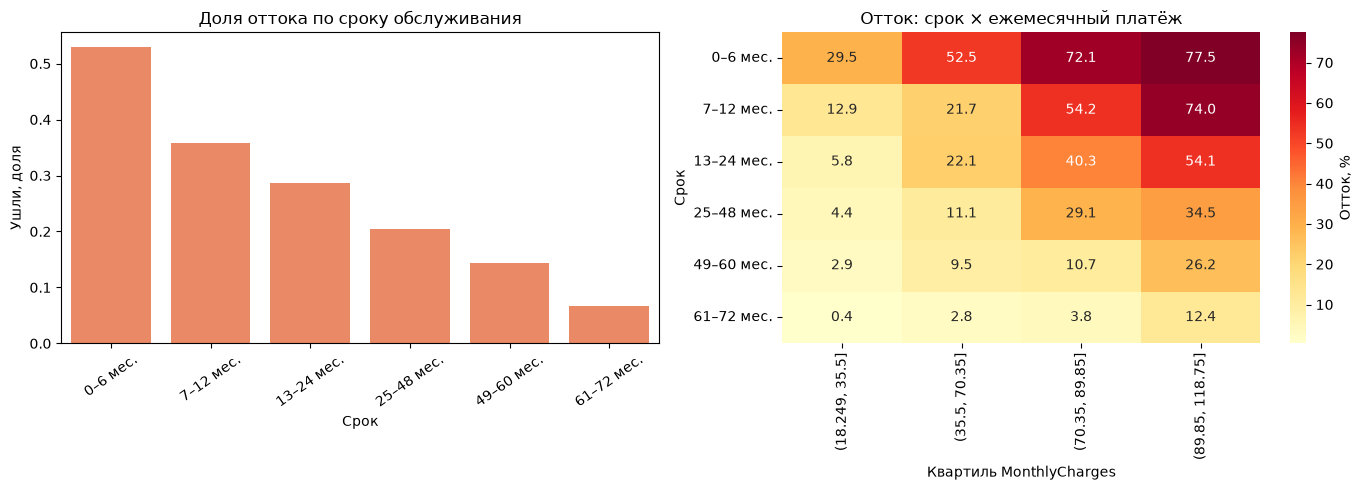

In [23]:
df_eda['TenureGroup'] = pd.cut(
    df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=['0–6 мес.', '7–12 мес.', '13–24 мес.', '25–48 мес.', '49–60 мес.', '61–72 мес.'],
    include_lowest=True
)
df_eda['MonthlyChargeGroup'] = pd.qcut(
    df_eda['MonthlyCharges'], q=4, duplicates='drop'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tenure_risk = (df_eda.groupby('TenureGroup', observed=False)['ChurnFlag']
               .agg(['mean', 'size']).reset_index())
sns.barplot(data=tenure_risk, x='TenureGroup', y='mean', ax=axes[0], color='coral')
axes[0].set(title='Доля оттока по сроку обслуживания', xlabel='Срок', ylabel='Ушли, доля')
axes[0].tick_params(axis='x', rotation=35)

charge_tenure = (df_eda.pivot_table(index='TenureGroup', columns='MonthlyChargeGroup',
                                    values='ChurnFlag', aggfunc='mean', observed=False) * 100)
sns.heatmap(charge_tenure, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Отток, %'})
axes[1].set(title='Отток: срок × ежемесячный платёж', xlabel='Квартиль MonthlyCharges', ylabel='Срок')
plt.tight_layout()
plt.show()


**Выводы:**  
Доля оттока последовательно снижается с увеличением срока обслуживания: от 53% среди клиентов со стажем до 6 месяцев до 7% среди клиентов, пользующихся услугами более 5 лет.  
При этом внутри каждой группы стажа наблюдается увеличение доли оттока с ростом ежемесячных платежей. Например, среди клиентов со сроком обслуживания 0–6 месяцев доля оттока составляет 29,5% в нижнем квартиле платежей и 77,5% в верхнем. Аналогичная закономерность прослеживается и в остальных группах стажа.  
Таким образом, наиболее высокая доля оттока наблюдается среди клиентов с небольшим сроком обслуживания и высокими ежемесячными платежами. Оба признака могут быть полезны для выявления абонентов с повышенным риском ухода.

## 6.3 Сочетания категориальных факторов

Проверяем совместное распределение договора и интернет-услуги. На тепловой карте показываем долю оттока внутри каждой комбинации; малые сегменты стоит трактовать осторожно.

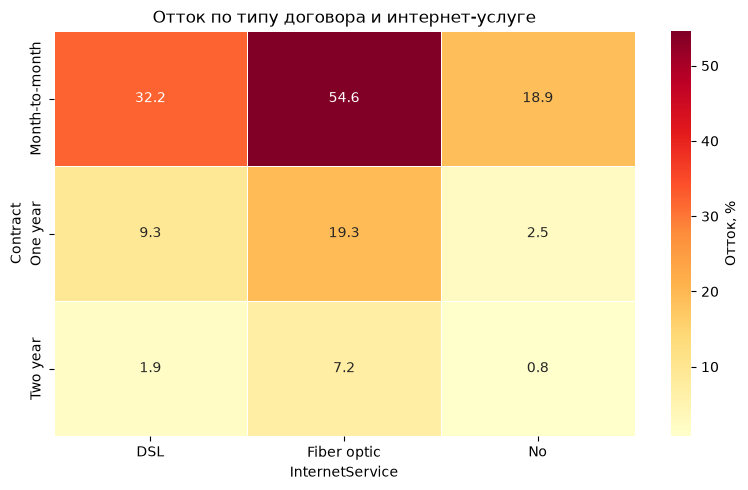

In [24]:
segment = (
    df_eda.pivot_table(index='Contract', columns='InternetService',
                       values='ChurnFlag', aggfunc='mean', observed=False) * 100
)
plt.figure(figsize=(8, 5))
sns.heatmap(segment, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': 'Отток, %'})
plt.title('Отток по типу договора и интернет-услуге')
plt.tight_layout()
plt.show()


**Выводы:**
При совместном анализе типа договора и интернет-подключения наблюдаются две закономерности.
Во-первых, доля оттока снижается с увеличением срока договора независимо от типа интернет-подключения. Например, среди пользователей Fiber optic она составляет 54,6% при помесячном договоре, 19,3% при годовом и 7,2% при двухлетнем.
Во-вторых, внутри каждой группы договоров доля оттока выше среди пользователей Fiber optic по сравнению с клиентами DSL и абонентами без интернет-подключения.
Наиболее высокая доля оттока (54,6%) наблюдается среди клиентов с помесячным договором и оптоволоконным интернетом.
Таким образом, сочетание типа договора и интернет-подключения позволяет выделить сегменты с повышенной долей оттока. Эти признаки стоит учитывать при построении модели прогнозирования.

Для оценки силы связи между категориальными признаками используем коэффициент V Крамера. Он принимает значения от 0 до 1: чем ближе значение к 0, тем слабее связь, а чем ближе к 1 — тем сильнее. Коэффициент позволяет сравнивать пары признаков, например тип договора и наличие оттока. Сам по себе V Крамера не показывает направление связи и не доказывает причинно-следственную зависимость, поэтому для интерпретации отдельных групп дополнительно рассматривались доли оттока.

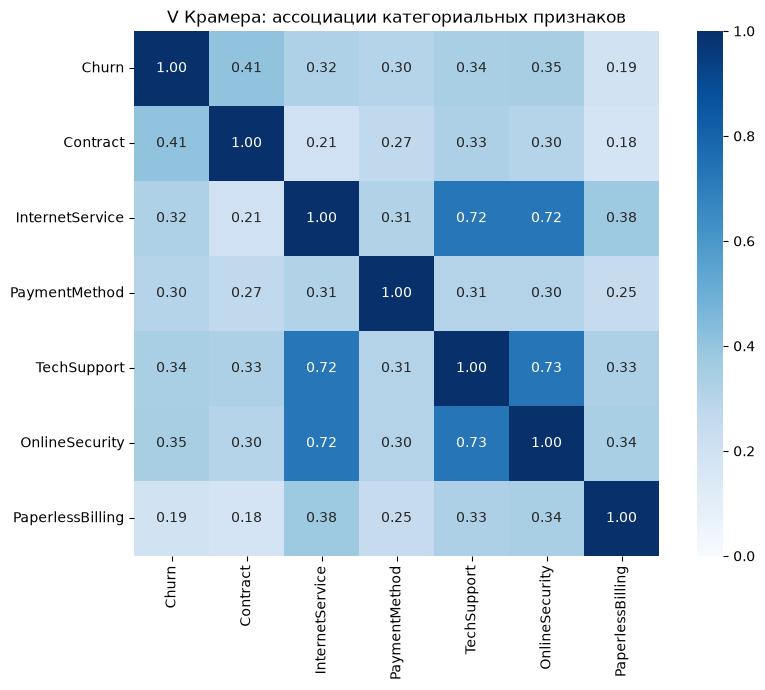

In [25]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.empty or min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

assoc_features = ['Churn', 'Contract', 'InternetService', 'PaymentMethod',
                  'TechSupport', 'OnlineSecurity', 'PaperlessBilling']
cramers = pd.DataFrame(index=assoc_features, columns=assoc_features, dtype=float)
for col1 in assoc_features:
    for col2 in assoc_features:
        cramers.loc[col1, col2] = cramers_v(df_eda[col1], df_eda[col2])

plt.figure(figsize=(9, 7))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True)
plt.title('V Крамера: ассоциации категориальных признаков')
plt.tight_layout()
plt.show()

По матрице V Крамера наиболее сильная связь с оттоком наблюдается у типа договора (`Contract`, V = 0,41). Далее следуют наличие онлайн-защиты (`OnlineSecurity`, 0,35), технической поддержки (`TechSupport`, 0,34), тип интернет-подключения (`InternetService`, 0,32) и способ оплаты (`PaymentMethod`, 0,30). Связь `PaperlessBilling` с оттоком слабее среди рассмотренных признаков (V = 0,19).

Между некоторыми услугами также обнаружена сильная ассоциация: V составляет 0,72 для пар `InternetService`—`TechSupport` и `InternetService`—`OnlineSecurity`, а для `TechSupport`—`OnlineSecurity` — 0,73. Значит, эти признаки могут нести частично совпадающую информацию.

**Выводы:**
Наиболее выраженная связь с целевым признаком Churn наблюдается у типа договора (`Contract`, V Крамера = 0,41). Умеренная связь прослеживается для признаков `OnlineSecurity` (0,35), `TechSupport` (0,34), `InternetService` (0,32) и `PaymentMethod` (0,30). Для `PaperlessBilling` связь слабее (0,19).  
Также выявлена тесная взаимосвязь между признаками `TechSupport`, `OnlineSecurity` и `InternetService` (V Крамера от 0,72 до 0,73). Это объясняется в том числе тем, что доступность дополнительных интернет-услуг зависит от наличия интернет-подключения.  
Полученные результаты дополняют предыдущий анализ и подтверждают, что тип договора, интернет-подключение и дополнительные услуги связаны с оттоком абонентов.  
При этом V Крамера характеризует силу связи между категориальными признаками, но не показывает её направление и не доказывает причинно-следственную зависимость.

# Сегментный анализ

## 7.1 Отток по числу базовых подключённых услуг

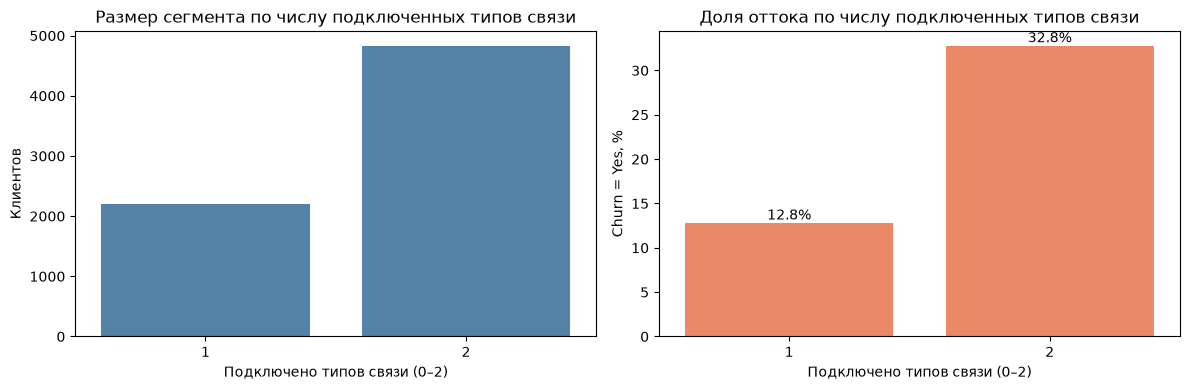

In [26]:
df_eda["HasInternet"] = df_eda["InternetService"].isin(
    ["DSL", "Fiber optic"]
).astype(int)
df_eda["HasPhone"] = df_eda["PhoneService"].eq("Yes").astype(int)
#df_eda["HasTV"] = df_eda["StreamingTV"].eq("Yes").astype(int)

#base_service_flags = ["HasInternet", "HasPhone", "HasTV"]
base_service_flags = ["HasInternet", "HasPhone"]
df_eda["NumBasicServices"] = df_eda[base_service_flags].sum(axis=1)
basic_service_summary = (
    df_eda.groupby('NumBasicServices', observed=False)
    .agg(Клиентов=('ChurnFlag', 'size'),
         Ушли=('ChurnFlag', 'sum'),
         Доля_оттока=('ChurnFlag', 'mean'))
    .reset_index()
)
basic_service_summary['Доля_оттока_pct'] = basic_service_summary['Доля_оттока'] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Клиентов',
            ax=axes[0], color='steelblue')
axes[0].set(title='Размер сегмента по числу подключенных типов связи',
            xlabel='Подключено типов связи (0–2)', ylabel='Клиентов')
sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Доля_оттока_pct',
            ax=axes[1], color='coral')
axes[1].set(title='Доля оттока по числу подключенных типов связи',
            xlabel='Подключено типов связи (0–2)', ylabel='Churn = Yes, %')
for bar in axes[1].patches:
    axes[1].annotate(f'{bar.get_height():.1f}%',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom')
plt.tight_layout()
plt.show()

**Выводы:**  
Большинство абонентов используют оба типа связи — интернет и телефон.  
Доля оттока среди клиентов с одним подключённым типом связи составляет 12,8%, тогда как среди клиентов с двумя типами связи — 32,8%.  
Таким образом, наличие обоих типов подключения связано с более высокой долей оттока. Однако полученный результат не позволяет однозначно определить, какой именно тип связи связан с повышенным риском ухода.  
Для более детального анализа необходимо учитывать состав подключённых услуг и другие характеристики абонентов.

In [27]:
conditions = [
    (df_eda["HasInternet"] == 1) & (df_eda["HasPhone"] == 0),
    (df_eda["HasInternet"] == 0) & (df_eda["HasPhone"] == 1),
    (df_eda["HasInternet"] == 1) & (df_eda["HasPhone"] == 1)
]

choices = [
    "Только интернет",
    "Только телефон",
    "Интернет и телефон"
]

df_eda["ConnectionGroup"] = np.select(
    conditions,
    choices,
    default="Нет подключений"
)

connection_summary = (
    df_eda.groupby("ConnectionGroup")
    .agg(
        Клиентов=("ChurnFlag", "size"),
        Ушли=("ChurnFlag", "sum"),
        Доля_оттока=("ChurnFlag", "mean")
    )
    .reset_index()
)

connection_summary["Доля_оттока_pct"] = (
    connection_summary["Доля_оттока"] * 100
)

display(
    connection_summary[
        ["ConnectionGroup", "Клиентов", "Ушли", "Доля_оттока_pct"]
    ].round(1)
)

,ConnectionGroup,Клиентов,Ушли,Доля_оттока_pct
0,Интернет и телефон,4835,1586,32.8
1,Только интернет,682,170,24.9
2,Только телефон,1526,113,7.4


**Выводы:**  
Дополнительный анализ состава подключений показал, что:  
среди клиентов, использующих только интернет, доля оттока составляет 24,9%;  
среди клиентов, использующих только телефон, — 7,4%;  
среди клиентов, использующих оба типа связи, — 32,8%.  
Таким образом, наиболее высокая доля оттока наблюдается среди абонентов, использующих интернет и телефон, а наиболее низкая — среди клиентов только с телефонной связью. Результаты указывают на более высокую долю оттока среди клиентов с интернет-подключением.  


## 7.2 Социально-демографические сегменты оттока

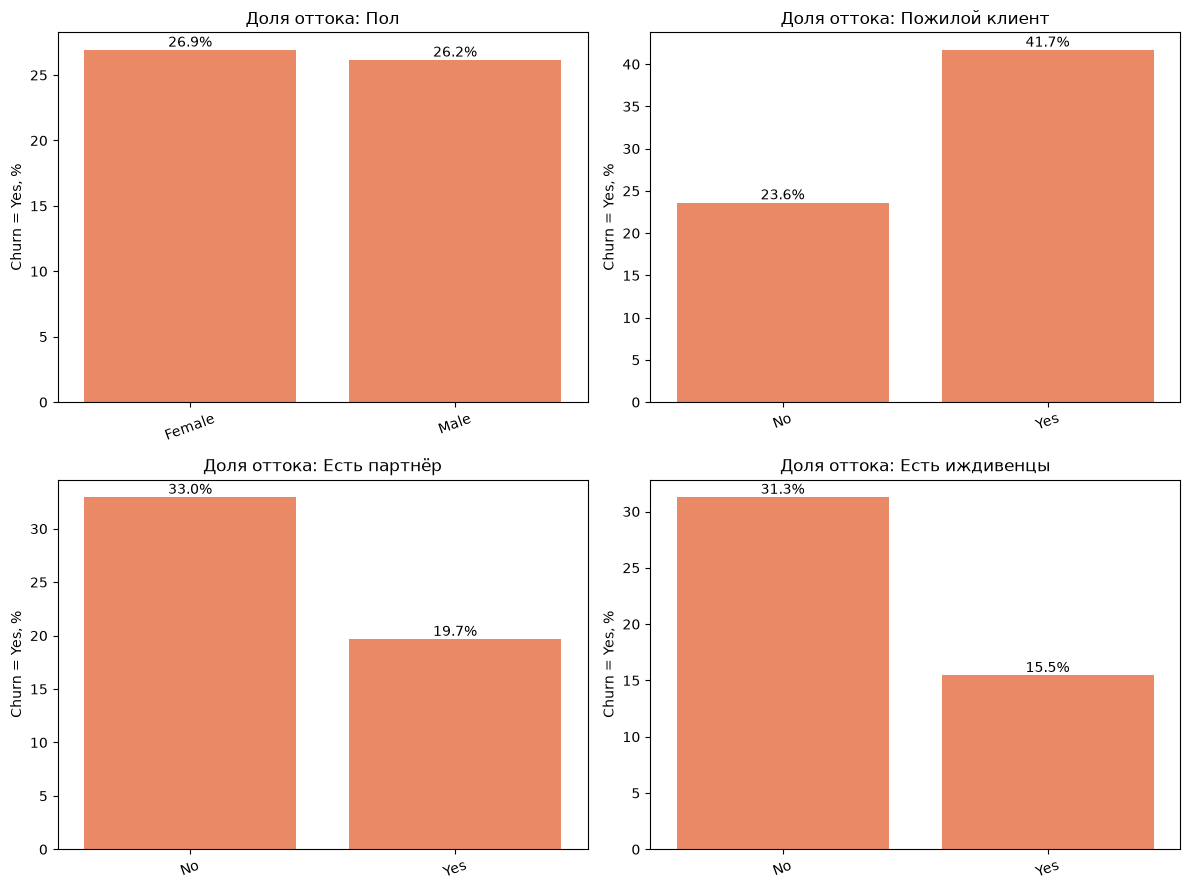

In [28]:
df_eda['SeniorCitizenGroup'] = df_eda['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
demo_features = ['gender', 'SeniorCitizenGroup', 'Partner', 'Dependents']
demo_labels = {
    'gender': 'Пол', 'SeniorCitizenGroup': 'Пожилой клиент',
    'Partner': 'Есть партнёр', 'Dependents': 'Есть иждивенцы'
}

demo_summaries = {}
for col in demo_features:
    summary = (
        df_eda.groupby(col, dropna=False, observed=False)
        .agg(Клиентов=('ChurnFlag', 'size'),
             Ушли=('ChurnFlag', 'sum'),
             Доля_оттока=('ChurnFlag', 'mean'))
        .reset_index()
    )
    summary['Доля_оттока_pct'] = summary['Доля_оттока'] * 100
    demo_summaries[col] = summary

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, demo_features):
    summary = demo_summaries[col]
    sns.barplot(data=summary, x=col, y='Доля_оттока_pct', ax=ax, color='coral')
    ax.set(title=f"Доля оттока: {demo_labels[col]}",
           xlabel='', ylabel='Churn = Yes, %')
    ax.tick_params(axis='x', rotation=20)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.1f}%',
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom')
plt.tight_layout()
plt.show()

**Выводы:**  
Среди рассмотренных социально-демографических признаков наиболее заметные различия в доле оттока наблюдаются по возрасту, наличию партнёра и иждивенцев.  
Доля оттока среди пожилых клиентов составляет 41,7%, что существенно выше показателя среди остальных абонентов (23,6%).  
Клиенты без партнёра чаще прекращают обслуживание: доля оттока составляет 33% против 19,7% среди клиентов с партнёром. Аналогичная закономерность наблюдается по наличию иждивенцев: 31,3% среди клиентов без иждивенцев против 15,5% среди клиентов с иждивенцами.  
По признаку пола существенных различий в доле оттока не выявлено.

## 7.3 Сочетания сегментов

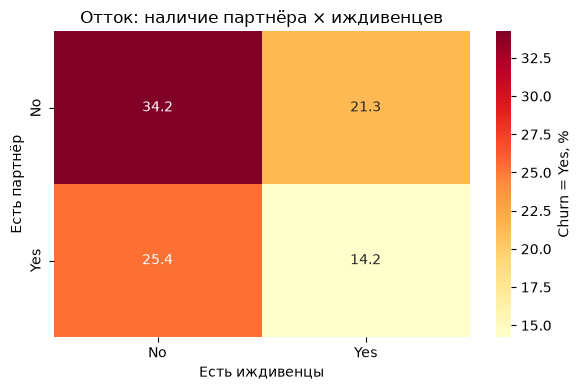

,Наличие партнёра,Наличие иждивенцев,Всего клиентов,Ушедшие клиенты,"Доля оттока, %"
0,Нет,Нет,3280,1123,34.2
1,Нет,Да,361,77,21.3
2,Да,Нет,1653,420,25.4
3,Да,Да,1749,249,14.2


In [29]:
demo_joint_churn = (
    df_eda.pivot_table(index='Partner', columns='Dependents', values='ChurnFlag',
                       aggfunc='mean', observed=False) * 100
)

plt.figure(figsize=(6, 4))
sns.heatmap(demo_joint_churn, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn = Yes, %'})
plt.title('Отток: наличие партнёра × иждивенцев')
plt.xlabel('Есть иждивенцы')
plt.ylabel('Есть партнёр')
plt.tight_layout()
plt.show()

demo_joint_summary = (
    df_eda.groupby(['Partner', 'Dependents'], observed=False)
    .agg(
        Клиентов=('ChurnFlag', 'size'),
        Ушли=('ChurnFlag', 'sum'),
        Доля_оттока=('ChurnFlag', 'mean')
    )
    .reset_index()
)

demo_joint_summary['Доля_оттока_pct'] = (
    demo_joint_summary['Доля_оттока'] * 100
)

demo_joint_summary = demo_joint_summary.rename(columns={
    'Partner': 'Наличие партнёра',
    'Dependents': 'Наличие иждивенцев',
    'Клиентов': 'Всего клиентов',
    'Ушли': 'Ушедшие клиенты',
    'Доля_оттока_pct': 'Доля оттока, %'
})
demo_joint_summary = demo_joint_summary.drop(columns=['Доля_оттока'])

demo_joint_summary['Наличие партнёра'] = (
    demo_joint_summary['Наличие партнёра'].map({'Yes': 'Да', 'No': 'Нет'})
)

demo_joint_summary['Наличие иждивенцев'] = (
    demo_joint_summary['Наличие иждивенцев'].map({'Yes': 'Да', 'No': 'Нет'})
)

display(demo_joint_summary.round(1))


**Выводы:**  
При совместном анализе наличия партнёра и иждивенцев наиболее высокая доля оттока наблюдается среди клиентов, не имеющих ни партнёра, ни иждивенцев (34,2%).  
Наличие иждивенцев связано с более низкой долей оттока как среди клиентов с партнёром (14,2% против 25,4%), так и среди клиентов без партнёра (21,3% против 34,2%).  
Аналогично, среди клиентов с партнёром доля оттока ниже независимо от наличия иждивенцев.  
Таким образом, сочетание социально-демографических характеристик позволяет выделить группы с разной долей оттока. В рамках проведённого анализа наиболее высокая доля оттока выявлена в сегменте клиентов без партнёра и иждивенцев.  
При интерпретации результатов следует учитывать, что численность групп неодинакова. В частности, группа клиентов без партнёра, но с иждивенцами, насчитывает всего 361 человека.

# 8. Сводка итогового датафрейма df_eda

## 8.1. Первый взгляд на данные

In [30]:
display(df_eda.head())
display(df_eda.sample(5, random_state=42))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,ChurnFlag,NumServices,MonthlyChargesChange,TenureGroup,MonthlyChargeGroup,HasInternet,HasPhone,NumBasicServices,ConnectionGroup,SeniorCitizenGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,0,2,0.00,0–6 мес.,"(18.249, 35.5]",1,0,1,Только интернет,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,0,4,-46.80,25–48 мес.,"(35.5, 70.35]",1,1,2,Интернет и телефон,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,1,4,0.45,0–6 мес.,"(35.5, 70.35]",1,1,2,Интернет и телефон,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,0,4,-62.75,25–48 мес.,"(35.5, 70.35]",1,0,1,Только интернет,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,1,2,10.25,0–6 мес.,"(70.35, 89.85]",1,1,2,Интернет и телефон,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,ChurnFlag,NumServices,MonthlyChargesChange,TenureGroup,MonthlyChargeGroup,HasInternet,HasPhone,NumBasicServices,ConnectionGroup,SeniorCitizenGroup
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,1,1,0.00,0–6 мес.,"(18.249, 35.5]",1,0,1,Только интернет,No
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,0,2,-38.80,25–48 мес.,"(18.249, 35.5]",0,1,1,Только телефон,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,0,1,25.50,49–60 мес.,"(18.249, 35.5]",0,1,1,Только телефон,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,1,3,0.00,0–6 мес.,"(70.35, 89.85]",1,1,2,Интернет и телефон,No
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,0,3,-126.75,61–72 мес.,"(35.5, 70.35]",1,1,2,Интернет и телефон,No


## 8.2. Технический паспорт данных

In [31]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   customerID            7043 non-null   object  
 1   gender                7043 non-null   object  
 2   SeniorCitizen         7043 non-null   int64   
 3   Partner               7043 non-null   object  
 4   Dependents            7043 non-null   object  
 5   tenure                7043 non-null   int64   
 6   PhoneService          7043 non-null   object  
 7   MultipleLines         7043 non-null   object  
 8   InternetService       7043 non-null   object  
 9   OnlineSecurity        7043 non-null   object  
 10  OnlineBackup          7043 non-null   object  
 11  DeviceProtection      7043 non-null   object  
 12  TechSupport           7043 non-null   object  
 13  StreamingTV           7043 non-null   object  
 14  StreamingMovies       7043 non-null   object  
 15  Cont

In [32]:
df_eda.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'ChurnFlag',
       'NumServices', 'MonthlyChargesChange', 'TenureGroup',
       'MonthlyChargeGroup', 'HasInternet', 'HasPhone', 'NumBasicServices',
       'ConnectionGroup', 'SeniorCitizenGroup'],
      dtype='object')

## **Основные выводы по результатам EDA**
В ходе исследовательского анализа данных выявлены следующие закономерности:  
1. Общая характеристика оттока  
Отток затрагивает 26,5% абонентов. Таким образом, примерно каждый четвёртый клиент прекращает обслуживание.
2. Факторы, связанные с оттоком  
Наиболее заметные различия в доле оттока наблюдаются в зависимости от:  
типа договора: клиенты с помесячной оплатой уходят чаще, чем клиенты с годовыми и двухлетними договорами;  
типа интернет-подключения: среди пользователей Fiber optic доля оттока выше, чем среди пользователей DSL и клиентов без интернета;  
способа оплаты: наиболее высокая доля оттока наблюдается среди клиентов, оплачивающих услуги электронным чеком;  
наличия дополнительных услуг: среди клиентов без технической поддержки и онлайн-защиты доля оттока выше.  
3. Числовые признаки  
Наиболее выраженная связь с оттоком наблюдается у срока обслуживания: среди клиентов с небольшим стажем доля оттока выше. Также выявлена связь между размером ежемесячных платежей и оттоком.  
4. Особенности клиентских сегментов  
Более высокая доля оттока наблюдается среди пожилых клиентов, абонентов без партнёра и иждивенцев. Среди клиентов, использующих интернет и телефон одновременно, доля оттока выше, чем среди клиентов только с телефонной связью.  
5. Подготовка к моделированию  
В ходе EDA исследованы распределения признаков, их взаимосвязи с целевой переменной и особенности отдельных клиентских сегментов. Сформированы и проверены дополнительные признаки, которые могут быть полезны при моделировании.  
Результаты EDA используются для определения подхода к предобработке данных, отбора признаков и последующей оценки качества модели.  
Важно учитывать, что выявленные закономерности отражают статистические взаимосвязи и не доказывают причинно-следственную зависимость оттока от отдельных характеристик клиентов.

---

# Часть 2. Построение модели прогнозирования оттока

После проведения разведочного анализа данных (EDA) переходим к машинному обучению. На этом этапе мы:
1. Подготовим таблицу признаков `X` и целевую переменную `y` (переведём текстовые категории в числа 0 и 1)
2. Разделим данные на обучающую (`Train`) и тестовую (`Test`) выборки со стратификацией по целевой переменной (`stratify=y`)
3. Выполним стандартизацию числовых признаков (`StandardScaler`)
4. Обучим и сравним baseline-модели: `DummyClassifier` и `LogisticRegression` (обычную и с балансировкой классов `class_weight='balanced'`)


## 9. Подготовка признаков (`X`) и целевой переменной (`y`)

В итоговом датафрейме `df_eda` сейчас 30 столбцов (включая идентификатор `customerID`, текстовый таргет `Churn` и вспомогательные группы, которые создавались только для  EDA). Отберём для моделирования только содержательные признаки:
- **Целевая переменная (`y`):** `ChurnFlag` (`0` - клиент остался, `1` - клиент ушёл)
- **Числовые признаки (3 шт.):** `tenure`, `MonthlyCharges`, `MonthlyChargesChange` (`TotalCharges` исключаем, так как мы заменили его на `MonthlyChargesChange`, чтобы избежать сильной линейной зависимости со "стажем" и ежемесячным платежом). 
- **Категориальные признаки (16 шт.):** пол, семейное положение, подключённые услуги, тип контракта и способ оплаты

Также перед кодированием упростим дополнительные услуги: значения `'No internet service'` и `'No phone service'` заменим на `'No'`, поскольку сам факт наличия интернета или телефонии уже отражён в столбцах `InternetService` и `PhoneService`



In [64]:
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
]
numeric_features = ['tenure', 'MonthlyCharges', 'MonthlyChargesChange', 'NumServices']

target = ['Churn']

df_model = df_eda[categorical_features + numeric_features + target].copy()
df_model[numeric_features] = df_model[numeric_features].astype(float)

# Посмотрим на данные ДО кодирования категориальных признаков
print('Размер таблицы до кодирования:', df_model.shape)
display(df_model.head(3))


Размер таблицы до кодирования: (7043, 21)


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,tenure,MonthlyCharges,MonthlyChargesChange,NumServices,Churn
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,...,No,No,Month-to-month,Yes,Electronic check,1.0,29.85,0.00,2.0,No
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,...,No,No,One year,No,Mailed check,34.0,56.95,-46.80,4.0,No
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,...,No,No,Month-to-month,Yes,Mailed check,2.0,53.85,0.45,4.0,Yes


In [65]:
# Заменяем дублирующие значения в дополнительных услугах на 'No'
internet_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
]

df_model[internet_cols] = df_model[internet_cols].replace('No internet service', 'No')
df_model['MultipleLines'] = df_model['MultipleLines'].replace('No phone service', 'No')

In [66]:
binary_str_cols = ['Partner', 'Dependents', 'PhoneService',
                   'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                   'DeviceProtection', 'TechSupport', 'StreamingTV',
                   'StreamingMovies', 'PaperlessBilling', 'Churn']

df_model[binary_str_cols] = df_model[binary_str_cols].replace({'Yes':1, 'No':0})

C:\Users\Дарино4ка\AppData\Local\Temp\ipykernel_4640\2403490390.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_model[binary_str_cols] = df_model[binary_str_cols].replace({'Yes':1, 'No':0})


In [67]:
X = pd.get_dummies(
    df_model,
    columns=['PaymentMethod', 'InternetService', 'Contract', 'gender'],
    dtype=int
    ).drop(['Churn', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'Contract_Two year', 'gender_Female'], axis=1)

y = df_model['Churn']

print('Размер матрицы признаков X после get_dummies:', X.shape)
print('Размер целевой переменной y:', y.shape)
print('Пропусков в X:', X.isna().sum().sum())
display(X.head())


Размер матрицы признаков X после get_dummies: (7043, 24)
Размер целевой переменной y: (7043,)
Пропусков в X: 0


,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,...,MonthlyChargesChange,NumServices,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,Contract_Month-to-month,Contract_One year,gender_Male
0,0,1,0,0,0,0,1,0,0,0,...,0.00,2.0,0,1,0,1,0,1,0,0
1,0,0,0,1,0,1,0,1,0,0,...,-46.80,4.0,0,0,1,1,0,0,1,1
2,0,0,0,1,0,1,1,0,0,0,...,0.45,4.0,0,0,1,1,0,1,0,1
3,0,0,0,0,0,1,0,1,1,0,...,-62.75,4.0,0,0,0,1,0,0,1,1
4,0,0,0,1,0,0,0,0,0,0,...,10.25,2.0,0,1,0,0,1,1,0,0


In [68]:
# Посмотрим список всех 23 итоговых признаков и статистику числовых столбцов
print('Список признаков в X:')
print(list(X.columns))

print('\nСтатистика числовых признаков (в исходных единицах измерения):')
display(X[numeric_features].describe().round(2))


Список признаков в X:
['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'tenure', 'MonthlyCharges', 'MonthlyChargesChange', 'NumServices', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_DSL', 'InternetService_Fiber optic', 'Contract_Month-to-month', 'Contract_One year', 'gender_Male']

Статистика числовых признаков (в исходных единицах измерения):


,tenure,MonthlyCharges,MonthlyChargesChange,NumServices
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,0.15,4.15
std,24.56,30.09,67.20,2.31
min,0.00,18.25,-370.85,1.00
25%,9.00,35.50,-28.60,2.00
50%,29.00,70.35,0.00,4.00
75%,55.00,89.85,28.50,6.00
max,72.00,118.75,373.25,9.00


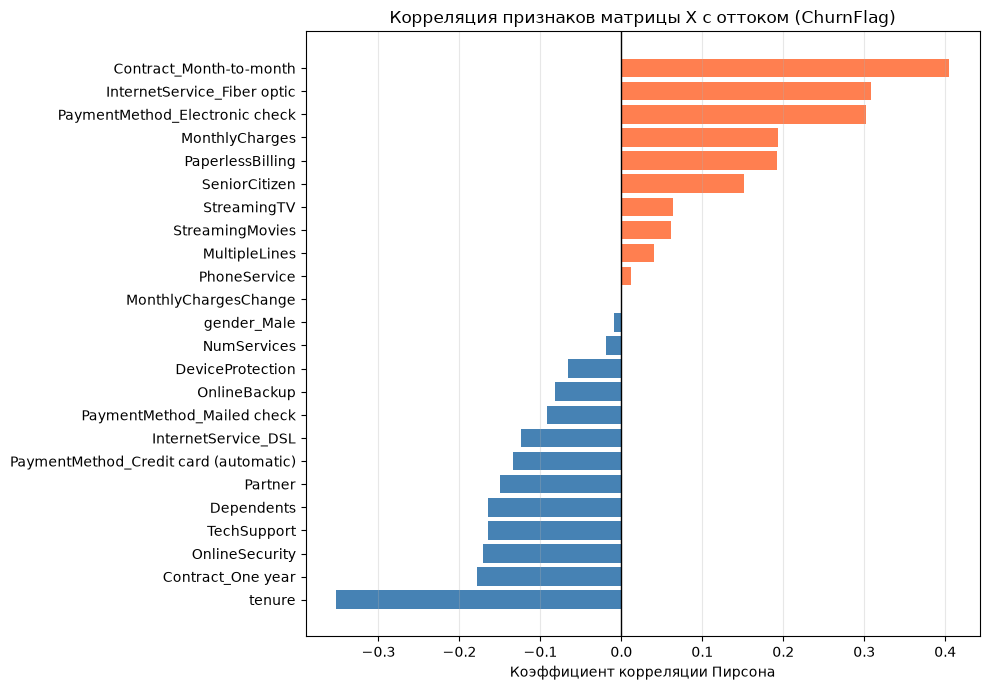

In [69]:
# Посмотрим, какие признаки в готовой матрице X сильнее всего коррелируют с целевой переменной y
corr_with_target = X.corrwith(y).sort_values()

plt.figure(figsize=(10, 7))
colors = ['steelblue' if val < 0 else 'coral' for val in corr_with_target]
plt.barh(corr_with_target.index, corr_with_target.values, color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Корреляция признаков матрицы X с оттоком (ChurnFlag)')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


Проверим взаимосвязи между всеми признаками. Используем коэффициент корреляции Phik (φk).

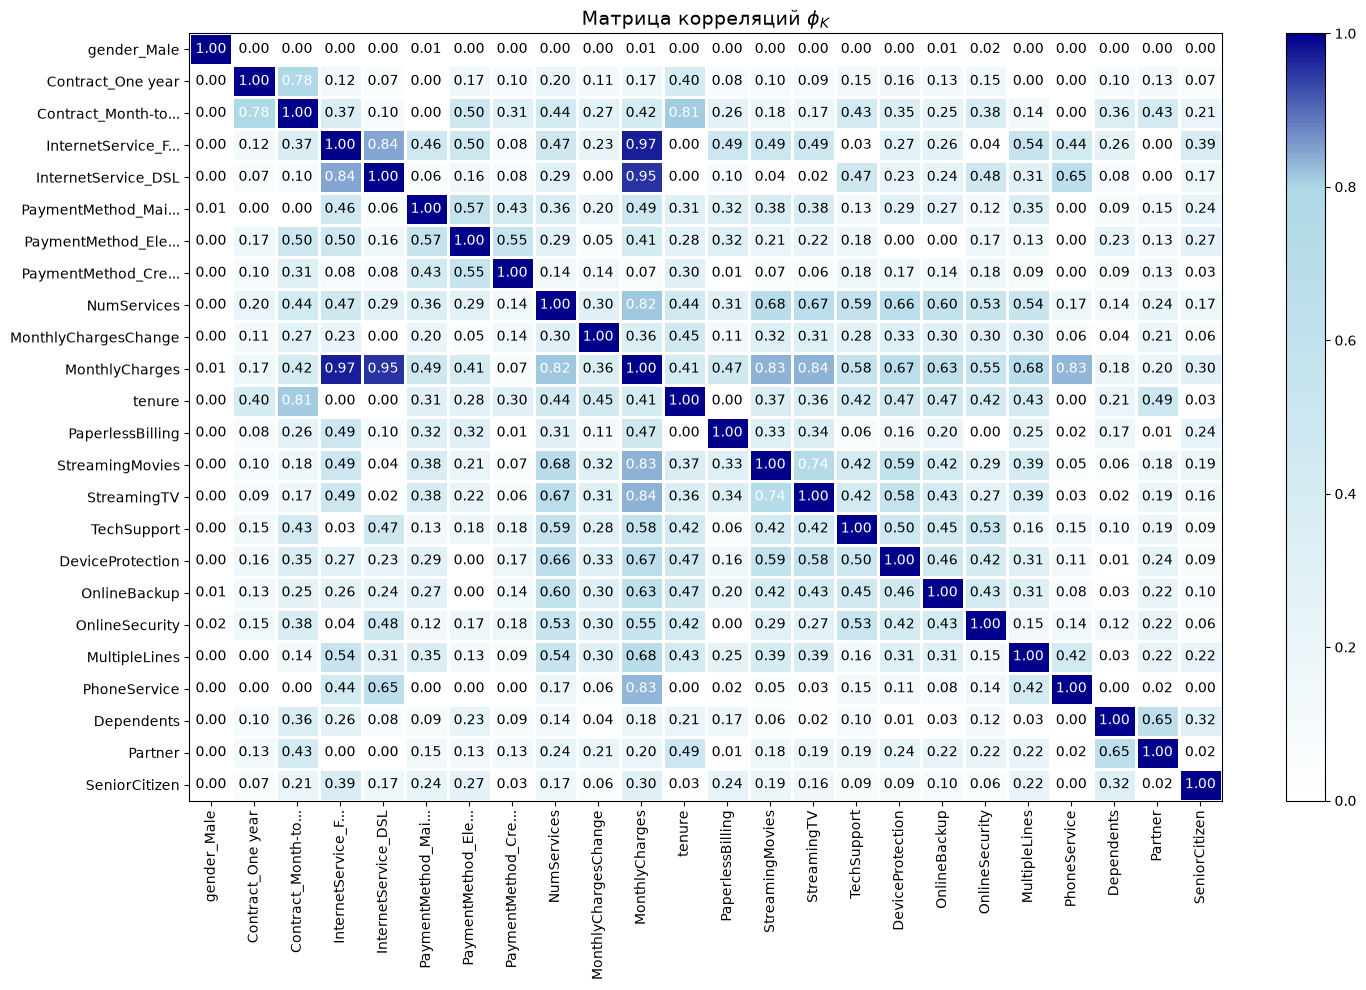

In [70]:
phik_overview = X.phik_matrix(interval_cols=X.columns)

threshold = 0.8
custom_cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    [
        (0.0, "white"),          
        (threshold, "lightblue"),    
        (1.0, "darkblue"),
    ]
)

plot_correlation_matrix(
    phik_overview.values,
    x_labels=phik_overview.columns,
    y_labels=phik_overview.index,
    vmin=0, vmax=1,
    color_map=custom_cmap,  # передаем кастомную карту
    title=r"Матрица корреляций $\phi_K$",
    fontsize_factor=1.0,
    figsize=(15, 10),
)
plt.tight_layout()
plt.show()

**Вывод по шагу 9:**
- Сформирована матрица признаков `X` размером **7 043 строки × 23 столбца** и целевой вектор `y` (`Churn`). Пропусков в данных нет, все признаки приведены к числовому виду
- По таблице `.describe()` видно, что числовые признаки пока имеют **сильно разный масштаб**: `tenure` меняется от `0` до `72` мес., `MonthlyCharges` - от `18.25` до `118.75` долл., а `MonthlyChargesChange` - от `-373` до `+373`. Поэтому перед обучением линейной модели их обязательно нужно стандартизировать
- По графику корреляций c таргетом уже видна логичная картина: сильнее всего с уходом положительно связаны `InternetService_Fiber optic`, `PaymentMethod_Electronic check` и `Contract_Month-to-month`, а сильнее всего против оттока работает `tenure`.


## 10. Разделение выборки (`train_test_split`, `stratify=y`) и стандартизация

Разделим выборку на обучающую (`Train`, 80%) и тестовую (`Test`, 20%). На `Train` модель будет учиться, а на `Test` (который модель не видела при обучении) мы честно проверим качество прогноза

Так как классы у нас несбалансированы (~26,5% ушедших против ~73,5% оставшихся), обязательно используем параметр **`stratify=y`** - он гарантирует, что доля оттока в `Train` и `Test` будет точно такой же, как во всём датасете

`MonthlyChargesChange` положим в отдельную переменную и проверим его вклад в качество модели на эксперименте.

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Сводная таблица по разбиению выборки
split_table = pd.DataFrame({
    'Выборка': ['Весь датасет', 'Train (80%)', 'Test (20%)'],
    'Всего клиентов': [len(y), len(y_train), len(y_test)],
    'Остались (0)': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Ушли (1)': [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    'Доля оттока, %': [
        round(y.mean() * 100, 2),
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2),
    ],
})

display(split_table)


,Выборка,Всего клиентов,Остались (0),Ушли (1),"Доля оттока, %"
0,Весь датасет,7043,5174,1869,26.54
1,Train (80%),5634,4139,1495,26.54
2,Test (20%),1409,1035,374,26.54


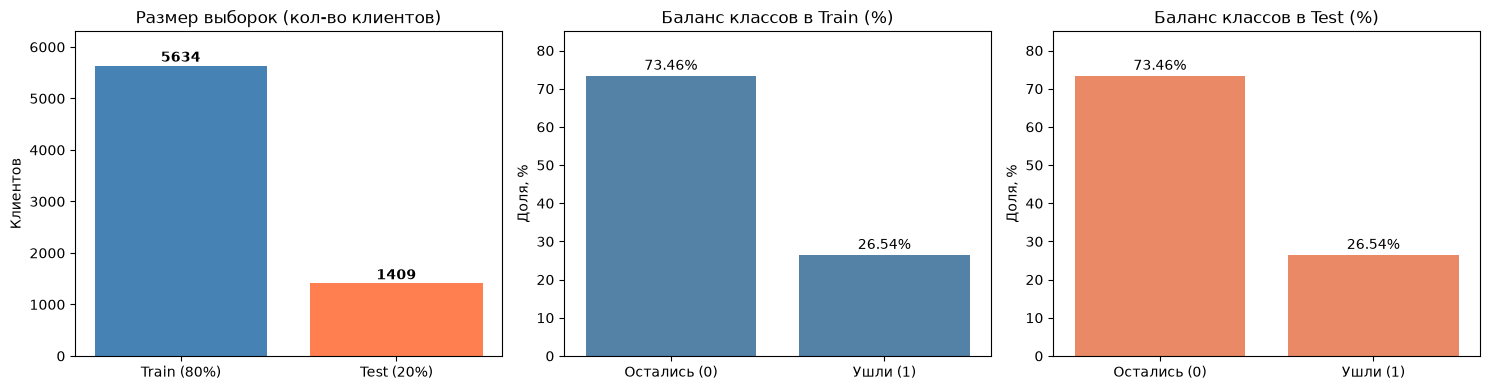

In [122]:
# Визуализируем размер выборок и сохранение баланса классов после стратификации
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Количество клиентов в Train и Test
axes[0].bar(['Train (80%)', 'Test (20%)'], [len(X_train), len(X_test)], color=['steelblue', 'coral'])
axes[0].set_title('Размер выборок (кол-во клиентов)')
axes[0].set_ylabel('Клиентов')
for i, v in enumerate([len(X_train), len(X_test)]):
    axes[0].text(i, v + 80, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 6300)

# 2. Доли классов в Train
train_shares = y_train.value_counts(normalize=True) * 100
sns.barplot(x=['Остались (0)', 'Ушли (1)'], y=train_shares.values, ax=axes[1], color='steelblue')
axes[1].set_title('Баланс классов в Train (%)')
axes[1].set_ylabel('Доля, %')
axes[1].set_ylim(0, 85)
for i, v in enumerate(train_shares.values):
    axes[1].text(i, v + 1.5, f'{v:.2f}%', ha='center')

# 3. Доли классов в Test
test_shares = y_test.value_counts(normalize=True) * 100
sns.barplot(x=['Остались (0)', 'Ушли (1)'], y=test_shares.values, ax=axes[2], color='coral')
axes[2].set_title('Баланс классов в Test (%)')
axes[2].set_ylabel('Доля, %')
axes[2].set_ylim(0, 85)
for i, v in enumerate(test_shares.values):
    axes[2].text(i, v + 1.5, f'{v:.2f}%', ha='center')

plt.tight_layout()
plt.show()


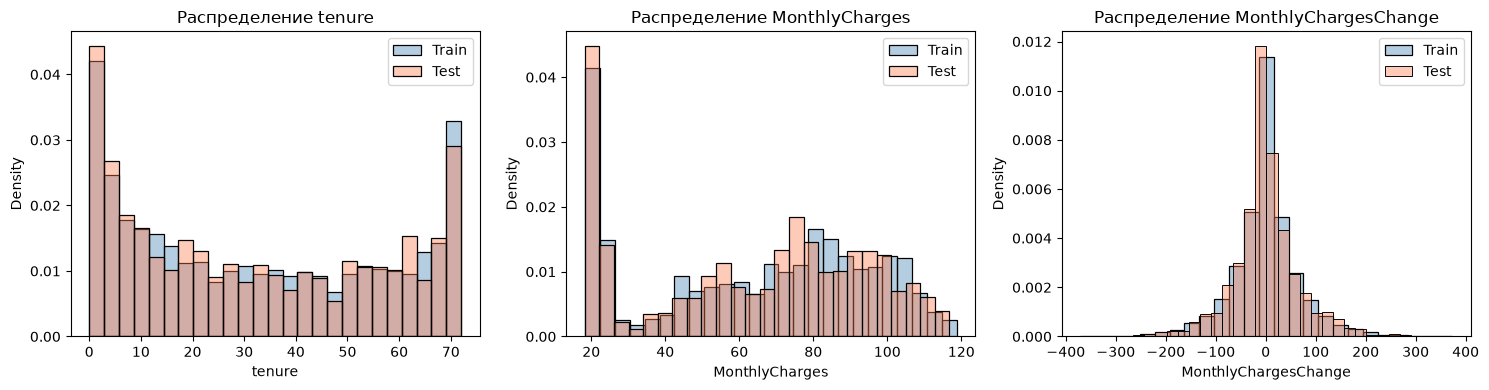

In [123]:
# Дополнительно убедимся, что числовые признаки распределены в Train и Test одинаково
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_features):
    sns.histplot(X_train[col], bins=25, stat='density', color='steelblue', alpha=0.4, label='Train', ax=ax)
    sns.histplot(X_test[col], bins=25, stat='density', color='coral', alpha=0.4, label='Test', ax=ax)
    ax.set_title(f'Распределение {col}')
    ax.legend()

plt.tight_layout()
plt.show()


**Вывод по разбиению выборки:**
- В обучающую выборку `Train` попало **5 634** клиента (4 139 остались и 1 495 ушли), в тестовую `Test` - **1 409** клиентов (1 035 остались и 374 ушли)
- Стратификация сработала точно: доля ушедших клиентов составляет **26,54%** и в `Train`, и в `Test`
- Гистограммы подтверждают, что распределения числовых признаков `tenure`, `MonthlyCharges` и `MonthlyChargesChange` в обеих выборках практически совпадают


## 11. Построим DummyClassifier

Перед построением каких-либо моделей проделаем основные шаги:
* создадим preprocessor для масштабирования признаков внутри Pipeline
* зададим StratifiedKFold, чтобы обеспечить расчет наиболее объективных метрик
* определим список метрик для расчета на фолдах в CV
* уберем пока фичи NumServices, MonthlyChargesChange. Проверим их в отдельных экспериментах
* проверим простейшую стратегию с `DummyClassifier` на обучающей выборке с помощью кросс-валидации, чтобы затем сравнить, насколько простая стратегия уступает Baseline модели

In [124]:
numeric_features = ['tenure', 'MonthlyCharges']
X_train_base, X_test_base = X_train.drop(['NumServices', 'MonthlyChargesChange'], axis=1), X_test.drop(['NumServices', 'MonthlyChargesChange'], axis=1)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ],
remainder='passthrough'
)

In [125]:
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [126]:
dummy_stratified = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(
        strategy='stratified',
        random_state=42
    ))
])

dummy_metrics = cross_validate(
        dummy_stratified,
        X_train_base, y_train,
        cv=cv,
        scoring=scoring
    )

pd.DataFrame({'Metrics': [
        dummy_metrics[f'test_{metric}'].mean()
        for metric in scoring
    ]
}, index=scoring.keys())

,Metrics
precision,0.274834
recall,0.277592
f1,0.276206
roc_auc,0.506517
pr_auc,0.268606


На Dummy модели были получены следующие метрики: `F1=0.276`, `ROC-AUC=0.507`. Финальная версия модели должна превосходить эти покзатели.

## 12. Построение Baseline модели

В качестве baseline обучим простую модель логистической регрессии с балансировкой классов (`class_weight='balanced'`). Пока не будет добавлять признаки MonthlyChargesChange и NumServices, проделаем эксперимент с их проверкой отдельно.  
Масштабирование признаков происходит здесь и на всех следующих этапах внутри Pipeline, чтобы избежать утечки данных.

In [127]:
lr_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

cv_baseline = cross_validate(
    lr_baseline,
    X_train_base,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

results_baseline = pd.DataFrame({
    'metrics': list(scoring.keys()),
    'mean_value_baseline': [ cv_baseline[f'test_{metric}'].mean().round(3) for metric in scoring]
    }
    )

print('Baseline: Logistic Regression (balanced)')
display(results_baseline)

Baseline: Logistic Regression (balanced)


,metrics,mean_value_baseline
0,precision,0.521
1,recall,0.793
2,f1,0.629
3,roc_auc,0.845
4,pr_auc,0.658


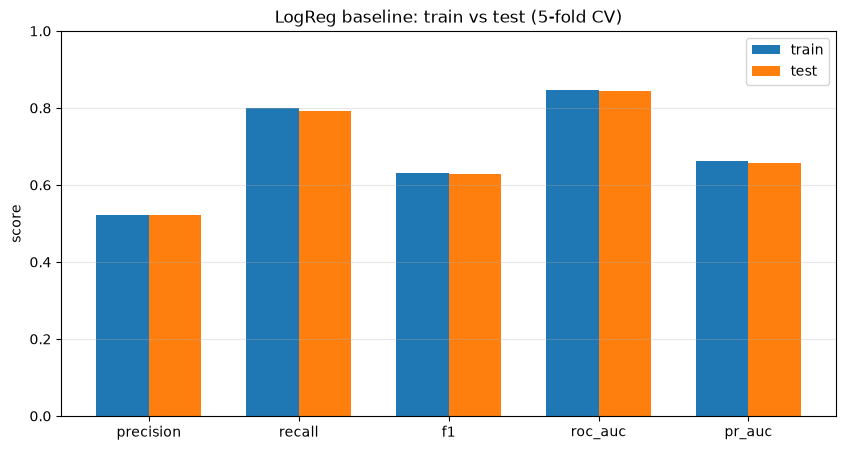

In [99]:
metrics = list(scoring.keys())
train_means = [cv_baseline[f'train_{m}'].mean() for m in metrics]
test_means  = [cv_baseline[f'test_{m}'].mean()  for m in metrics]

x = np.arange(len(metrics))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, train_means, w, label='train')
ax.bar(x + w/2, test_means,  w, label='test')
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1); ax.set_ylabel('score')
ax.set_title('LogReg baseline: train vs test (5-fold CV)')
ax.legend(); ax.grid(axis='y', alpha=.3)
plt.show()

На Baseline при пороге 0.5 `F1 = 0.629 ` и `ROC-AUC = 0.845`, результат существенно превосходит DummyClassifier. При этом уже на бэйзлайн модели `Recall = 0.793`, что является достаточно хорошим результатом на текущем этапе.  
На графике видно, что переобучения нет. Разница между train и test (CV) практически нулевая по всем метрикам - модель не запоминает тренировочные данные.

## 13. Feature engineering

Проведем эксперимент по добавлению новых фичей и оценим их вклад в качество модели. Проверим две фичи: MonthlyChargesChange (изменение месячного платежа) и NumServices (количество подключенных услуг). Обе модели обучаются на той же архитектуре (логистическая регрессия, L2, lbfgs, class_weight='balanced'), с тем же препроцессингом и на том же объекте cv, что обеспечивает сопоставимость с baseline версией.

### 13.1 Проверка фичи MonthlyChargesChange

In [128]:
numeric_features = numeric_features + ['MonthlyChargesChange']
X_train_base['MonthlyChargesChange'] = X_train['MonthlyChargesChange']

In [129]:
preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features)
        ],
remainder='passthrough'
    )

In [130]:
lr_change = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))
])

cv_change = cross_validate(
    lr_change,
    X_train_base, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

results_change = pd.DataFrame({
    'metrics': list(scoring.keys()),
    'mean_value_change': [ cv_change[f'test_{metric}'].mean().round(3) for metric in scoring]
    }
    )

print('Logistic Regression (balanced) with MonthlyChargesChange')
display(results_change.merge(results_baseline))

Logistic Regression (balanced) with MonthlyChargesChange


,metrics,mean_value_change,mean_value_baseline
0,precision,0.520,0.521
1,recall,0.795,0.793
2,f1,0.628,0.629
3,roc_auc,0.844,0.845
4,pr_auc,0.657,0.658


### 13.2 Проверка фичи NumServices

In [131]:
numeric_features = numeric_features + ['NumServices']

In [132]:
preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features)
        ],
remainder='passthrough'
    )

In [134]:
lr_numservices = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))
])

cv_numservices = cross_validate(
    lr_numservices,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

results_numservices = pd.DataFrame({
    'metrics': list(scoring.keys()),
    'mean_value_numservices': [ cv_numservices[f'test_{metric}'].mean().round(3) for metric in scoring]
    }
    )

print('Logistic Regression (balanced) with NumServices')
display(results_baseline.merge(results_numservices))

Logistic Regression (balanced) with NumServices


,metrics,mean_value_baseline,mean_value_numservices
0,precision,0.521,0.519
1,recall,0.793,0.795
2,f1,0.629,0.628
3,roc_auc,0.845,0.844
4,pr_auc,0.658,0.657


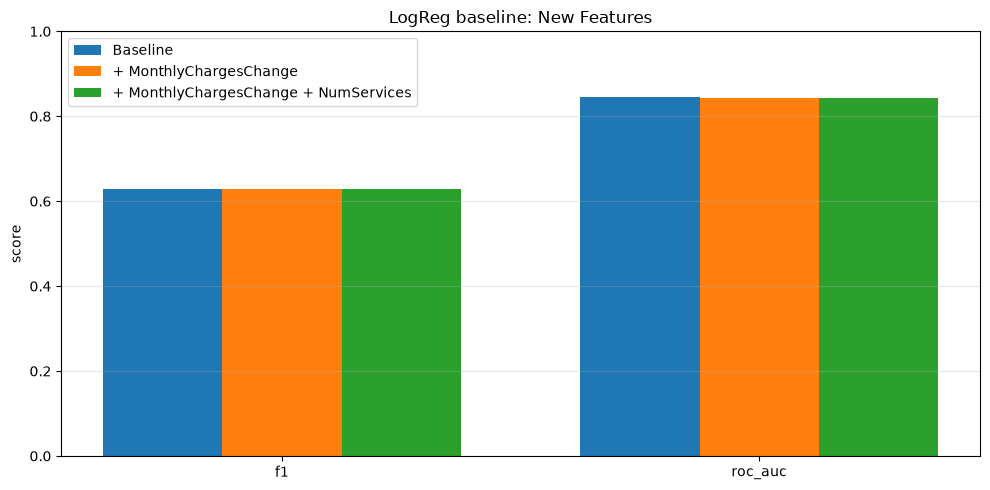

In [135]:
metrics = ['f1', 'roc_auc']
baseline_means = results_baseline[results_baseline['metrics'].isin(metrics)]['mean_value_baseline']
change_means = results_change[results_change['metrics'].isin(metrics)]['mean_value_change']
numservice_means = results_numservices[results_numservices['metrics'].isin(metrics)]['mean_value_numservices']

x = np.arange(len(metrics))
w = 0.25 

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - w, baseline_means,   w, label='Baseline')
ax.bar(x,     numservice_means, w, label='+ MonthlyChargesChange')
ax.bar(x + w, change_means,     w, label='+ MonthlyChargesChange + NumServices')

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel('score')
ax.set_title('LogReg baseline: New Features')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод:** признаки MonthlyChargesChange, NumServices вовсе не повлияли на результаты модели. F1, ROC-AUC имеют изменения в пределах погрешности, поэтому нецелесообразно добавлять их в модель. Оставим базовый набор фичей в обучении для большей стабильности.


In [ ]:
X_train = X_train.drop(['NumServices', 'MonthlyChargesChange'], axis=1)
X_test = X_test.drop(['NumServices', 'MonthlyChargesChange'], axis=1)
numeric_features.remove('NumServices')
numeric_features.remove('MonthlyChargesChange')

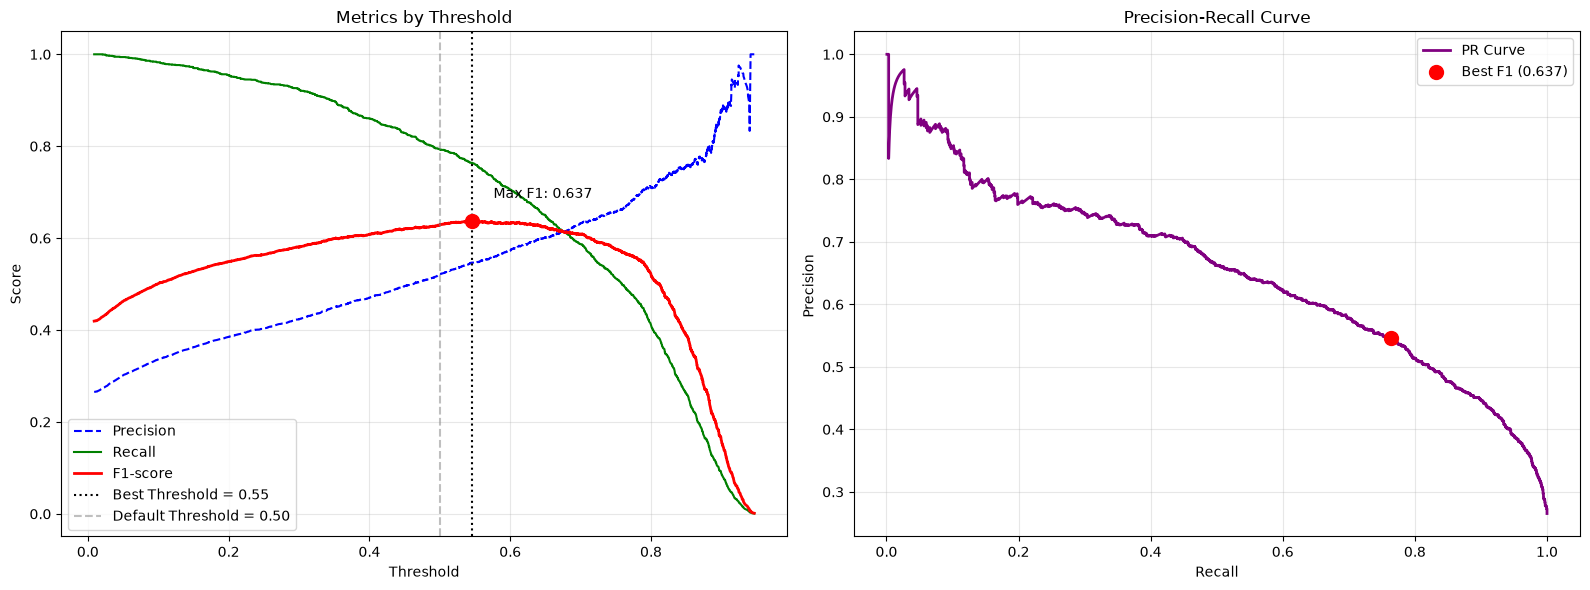

Оптимальный порог по F1: 0.546
Максимальный F1 на тесте: 0.637


In [140]:
y_train_bin = (y_train == 1).astype(int)
y_proba = cross_val_predict(lr_baseline, X_train, y_train_bin, cv=cv, method='predict_proba')[:, 1]
y_test_bin = y_train_bin 

precision, recall, thresholds = precision_recall_curve(y_test_bin, y_proba)

precision = precision[:-1]
recall = recall[:-1]

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(thresholds, precision, 'b--', label='Precision')
axes[0].plot(thresholds, recall, 'g-', label='Recall')
axes[0].plot(thresholds, f1_scores, 'r-', linewidth=2, label='F1-score')

# Отмечаем точку лучшего F1
axes[0].axvline(x=best_threshold, color='black', linestyle=':', label=f'Best Threshold = {best_threshold:.2f}')
axes[0].scatter(best_threshold, best_f1, color='red', s=100, zorder=5)
axes[0].annotate(f'Max F1: {best_f1:.3f}', 
                 xy=(best_threshold, best_f1), 
                 xytext=(best_threshold + 0.03, best_f1 + 0.05))

axes[0].axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='Default Threshold = 0.50')

axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Metrics by Threshold')
axes[0].legend(loc='lower left')
axes[0].grid(True, alpha=0.3)


axes[1].plot(recall, precision, color='purple', lw=2, label='PR Curve')
axes[1].scatter(recall[best_idx], precision[best_idx], color='red', s=100, zorder=5, 
                label=f'Best F1 ({best_f1:.3f})')

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision ')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Оптимальный порог по F1: {best_threshold:.3f}")
print(f"Максимальный F1 на тесте: {best_f1:.3f}")

На левом графике представлена динамика метрик Precision, Recall и F1 в зависимости от трешхолда. На дефолтном пороге 0.50 модель демонстрирует смещение в сторону Recall (= 0.79) при точности около 0.52. Максимальный F1 (0.637) достигается на трешхолде 0.55, это происходит за счет роста точности и падения полноты (более приоритетная метрика для оттока). 

На правом графике изображена кривая Precision-Recall. Расположение кривой существенно выше уровня случайного угадывания говорит о хорошей разделяющей способности модели.

## 14. Подбор гиперпараметров, регуляризация и добавление полиномов

Проверим полиноминальные признаки, подберем гиперпараметры внутри GridSearch. Для этого создадим два отдельный трансформера - для случаев с добавлением полиноминальных признаков (`preprocessor_poly`) и без них (`preprocessor_plain`).

In [146]:
preprocessor_plain = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ],
    remainder='passthrough'
)

preprocessor_poly = ColumnTransformer(
    transformers=[
        ('num_poly', Pipeline(steps=[
            ('scaler_before', StandardScaler()),
            ('poly', PolynomialFeatures(include_bias=False)),
            ('scaler_after', StandardScaler())
        ]), ['tenure', 'MonthlyCharges']),
    ],
remainder='passthrough'
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_plain),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

In [147]:
param_grid = [
    
    {
        'preprocessor': [preprocessor_plain],
        'classifier__solver': ['lbfgs', 'liblinear'],
        'classifier__l1_ratio': [0.0],
        'classifier__C': [0.01, 0.1, 0.5, 1.0, 2.0, 10.0],
        'classifier__class_weight': ['balanced', None],
        'classifier__max_iter': [2000],
    },
    
    {
        'preprocessor': [preprocessor_plain],
        'classifier__solver': ['liblinear'],
        'classifier__l1_ratio': [1.0],
        'classifier__C': [0.01, 0.1, 0.5, 1.0, 2.0, 10.0],
        'classifier__class_weight': ['balanced', None],
        'classifier__max_iter': [2000],
    },
    
    {
        'preprocessor': [preprocessor_poly],
        'preprocessor__num_poly__poly__degree': [1, 2],
        'classifier__solver': ['lbfgs', 'liblinear'],
        'classifier__l1_ratio': [0.0],
        'classifier__C': [0.01, 0.1, 0.5, 1.0, 2.0, 10.0],
        'classifier__class_weight': ['balanced', None],
        'classifier__max_iter': [2000],
    },
    
    {
        'preprocessor': [preprocessor_poly],
        'preprocessor__num_poly__poly__degree': [1, 2],
        'classifier__solver': ['liblinear'],
        'classifier__l1_ratio': [1.0],
        'classifier__C': [0.01, 0.1, 0.5, 1.0, 2.0, 10.0],
        'classifier__class_weight': ['balanced', None],
        'classifier__max_iter': [2000],
    }
    
]

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

grid.fit(X_train, y_train_bin)

print("ЛУЧШИЕ ПАРАМЕТРЫ")
for param, value in grid.best_params_.items():
    print(f"{param}: {value}")
print(f"\nbest_score_ (f1): {grid.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
ЛУЧШИЕ ПАРАМЕТРЫ
classifier__C: 0.1
classifier__class_weight: balanced
classifier__l1_ratio: 0.0
classifier__max_iter: 2000
classifier__solver: liblinear
preprocessor: ColumnTransformer(remainder='passthrough',
                  transformers=[('num_poly',
                                 Pipeline(steps=[('scaler_before',
                                                  StandardScaler()),
                                                 ('poly',
                                                  PolynomialFeatures(include_bias=False)),
                                                 ('scaler_after',
                                                  StandardScaler())]),
                                 ['tenure', 'MonthlyCharges'])])
preprocessor__num_poly__poly__degree: 2

best_score_ (f1): 0.6343


In [148]:
results = pd.DataFrame(grid.cv_results_)

cols = [
    'param_preprocessor__num_poly__poly__degree',
    'param_classifier__solver',
    'param_classifier__l1_ratio',
    'param_classifier__C',
    'mean_test_f1', 
    'mean_test_roc_auc',
]

print("ТОП-10 КОМБИНАЦИЙ ПО F1 (mean на CV)")
top10 = results[cols].sort_values('mean_test_f1', ascending=False).head(10)
top10.index = top10.index + 1
display(top10.round(4))

ТОП-10 КОМБИНАЦИЙ ПО F1 (mean на CV)


,param_preprocessor__num_poly__poly__degree,param_classifier__solver,param_classifier__l1_ratio,param_classifier__C,mean_test_f1,mean_test_roc_auc
48,2.0,liblinear,0.0,0.10,0.6343,0.8469
1,NaN,lbfgs,0.0,0.01,0.6341,0.8421
37,1.0,lbfgs,0.0,0.01,0.6341,0.8421
98,2.0,liblinear,1.0,1.00,0.6336,0.8473
54,2.0,lbfgs,0.0,0.50,0.6334,0.8474
62,2.0,lbfgs,0.0,1.00,0.6333,0.8474
70,2.0,lbfgs,0.0,2.00,0.6332,0.8476
40,2.0,liblinear,0.0,0.01,0.6331,0.8432
45,1.0,lbfgs,0.0,0.10,0.6330,0.8444
5,NaN,lbfgs,0.0,0.10,0.6330,0.8444


Лучшие гиперпараметры модели:
* classifier__C: 0.1 (умеренная L2-регуляризация)
* classifier__solver: liblinear
* полиномы 2-ой степени для tenure и MonthlyCharges.

Лучший F1 = 0.6343.


При этом выгода от полиномов символическая: обычная модель без полиномов (F1 = 0.6341) уступает всего на 0.0002. Дополнительная сложность ради такого маленького прироста по F1 не оправдана: она усложняет пайплайн и повышает риск нестабильности коэффициентов.

После подбора гиперпараметров видно плато качества: разброс значений F1 среди топ-10 комбинаций параметров крайне мал (0.6330-0.6343). Можно сказать, что модель стабильна и низко чувствительна к точным значениям коэффициента регуляризации и выбору солвера.

Оптимальным решением будет выбрать более простую модель без полиномов с F1 = 0.6341 (solver=lbfgs, C = 0.01)

Сравнение модели с полиномами и без них


,metric,plain_train,plain_cv,poly_train,poly_cv,gap cv (poly - plain)
0,f1,0.6341,0.6314,0.6366,0.6343,0.0029
1,roc_auc,0.8473,0.8442,0.8506,0.8469,0.0026
2,precision,0.5274,0.5258,0.5310,0.5295,0.0038
3,recall,0.7948,0.7906,0.7948,0.7913,0.0007


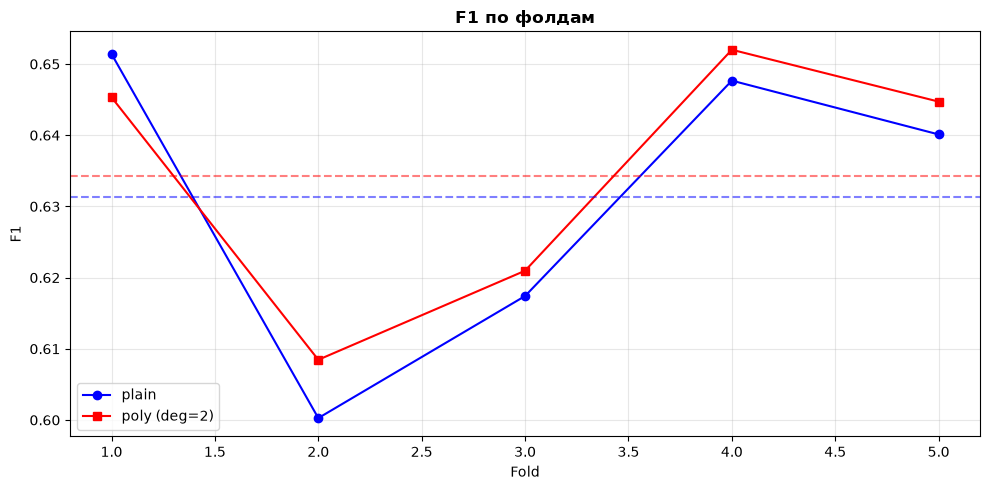

In [149]:
best_clf_params = {
    k.replace('classifier__', ''): v
    for k, v in grid.best_params_.items()
    if k.startswith('classifier__')
}

model_plain = Pipeline([
    ('preprocessor', preprocessor_plain),
    ('classifier', LogisticRegression(**best_clf_params, random_state=42))
])

best_degree = grid.best_params_.get('preprocessor__num_poly__poly__degree', 2)
preprocessor_poly.set_params(num_poly__poly__degree=best_degree)

model_poly = Pipeline([
    ('preprocessor', preprocessor_poly),
    ('classifier', LogisticRegression(**best_clf_params, random_state=42))
])

scoring = ['f1', 'roc_auc', 'precision', 'recall']

res_plain = cross_validate(
    model_plain, X_train, y_train_bin,
    cv=cv, scoring=scoring,
    return_train_score=True, n_jobs=-1
)
res_poly = cross_validate(
    model_poly, X_train, y_train_bin,
    cv=cv, scoring=scoring,
    return_train_score=True, n_jobs=-1
)

rows = []
for metric in scoring:
    rows.append({
        'metric': metric,
        'plain_train': res_plain[f'train_{metric}'].mean(),
        'plain_cv':    res_plain[f'test_{metric}'].mean(),
        'poly_train':  res_poly[f'train_{metric}'].mean(),
        'poly_cv':     res_poly[f'test_{metric}'].mean(),
        'gap cv (poly - plain)': res_poly[f'test_{metric}'].mean() - res_plain[f'test_{metric}'].mean(),
    })

cmp_df = pd.DataFrame(rows).round(4)
print(f"Сравнение модели с полиномами и без них")
display(cmp_df)

# график по фолдам
fig, axes = plt.subplots(figsize=(10, 5))

axes.plot(range(1, 6), res_plain['test_f1'], 'o-', color='blue', label='plain')
axes.plot(range(1, 6), res_poly['test_f1'],  's-', color='red',  label=f'poly (deg={best_degree})')
axes.axhline(res_plain['test_f1'].mean(), color='blue', linestyle='--', alpha=0.5)
axes.axhline(res_poly['test_f1'].mean(),  color='red',  linestyle='--', alpha=0.5)
axes.set_xlabel('Fold')
axes.set_ylabel('F1')
axes.set_title('F1 по фолдам', fontweight='bold')
axes.legend()
axes.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

Модель с полиномами чуть лучше по CV-метрикам: F1 0.6343 против 0.6314, ROC-AUC 0.8469 против 0.8424. Но разрыв между train и CV у обеих моделей минимальный (gap < 0.003) - переобучения нет.

Кривые метрик по фолдам движутся синхронно для poly и plain: обе проваливаются на фолде 2 (худший фолд для обеих версий) и поднимаются на фолде 4. Это значит, что разброс по фолдам определяется составом подвыборки, а не моделью, т.е. какие-то объекты в выборке просто сложнее.

Модель с полиномами лучше на 4 из 5 фолдов, но преимущество везде в пределах 0.002-0.004, т.е. это скорее шум, чем значимый результат.

## 15. Проверка оптимальной версии модели

Оставим лучшую модель без полиномов после подбора гиперпараметров и посчитаем метрики.

In [154]:
res = pd.DataFrame(grid.cv_results_)

mask_plain = res['param_preprocessor__num_poly__poly__degree'].isna()
plain_res = res[mask_mask := mask_plain].sort_values('mean_test_f1', ascending=False)
best_plain_idx = plain_res.index[0]

best_plain_params = {k: v for k, v in res.loc[best_plain_idx, 'params'].items()}
print("Лучшие параметры без полиномов:")
for k, v in best_plain_params.items():
    print(f"  {k}: {v}")
print(f"F1 (mean CV) = {res.loc[best_plain_idx, 'mean_test_f1']:.4f}")

best_model_plain = grid.best_estimator_
best_model_plain.set_params(**best_plain_params)

Лучшие параметры без полиномов:
  classifier__C: 0.01
  classifier__class_weight: balanced
  classifier__l1_ratio: 0.0
  classifier__max_iter: 2000
  classifier__solver: lbfgs
  preprocessor: ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['tenure', 'MonthlyCharges'])])
F1 (mean CV) = 0.6341


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature req

TRAIN vs CV


,metric,train_mean,cv_mean,gap (train - cv),cv_std
0,f1,0.6344,0.6341,0.0003,0.0174
1,roc_auc,0.8441,0.8421,0.0020,0.0116
2,precision,0.5303,0.5307,-0.0004,0.0144
3,recall,0.7895,0.7880,0.0015,0.0275


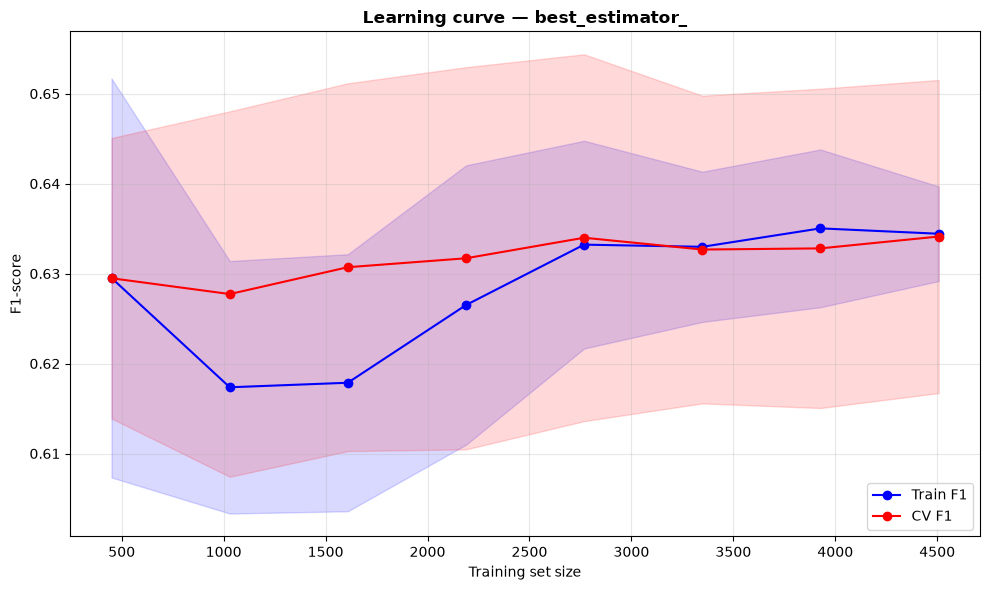

In [155]:
cv_res = cross_validate(
    best_model_plain,
    X_train, y_train_bin,
    cv=cv,
    scoring=['f1', 'roc_auc', 'precision', 'recall'],
    return_train_score=True,
    n_jobs=-1,
)

rows = []
for metric in ['f1', 'roc_auc', 'precision', 'recall']:
    train_mean = cv_res[f'train_{metric}'].mean()
    test_mean  = cv_res[f'test_{metric}'].mean()
    rows.append({
        'metric': metric,
        'train_mean': round(train_mean, 4),
        'cv_mean': round(test_mean, 4),
        'gap (train - cv)': round(train_mean - test_mean, 4),
        'cv_std': round(cv_res[f'test_{metric}'].std(), 4),
    })

diag_df = pd.DataFrame(rows)
print("TRAIN vs CV")
display(diag_df)



train_sizes, train_scores, val_scores = learning_curve(
    grid.best_estimator_,
    X_train, y_train_bin,
    cv=cv,
    scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    shuffle=True,
    random_state=42,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(train_sizes, train_mean, 'o-', color='blue', label='Train F1')
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color='blue')
ax.plot(train_sizes, val_mean, 'o-', color='red', label='CV F1')
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                alpha=0.15, color='red')

ax.set_xlabel('Training set size')
ax.set_ylabel('F1-score')
ax.set_title('Learning curve — best_estimator_', fontweight='bold')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
   

Для оценки стабильности модели была построена кривая обучения модели с лучшими гиперпараметрами без полиномов по метрике F1 при нарастающих объёмах трэйна.
Разрыв между качеством на обучающей выборке и на кросс-валидации практически отсутствует (gap по F1 - 0.0003, по ROC-AUC - 0.002), что говорит об отсутствии переобучения - модель не запоминает данные и хорошо обобщает.
Обе линии train и CV выходят на плато примерно с 2700 - 3000 наблюдений и далее изменяются незначительно. Это говорит об устойчивости модели к составу выборки.


Вывод: `модель стабильно показывает F1 ~ 0.63 и ROC-AUC ~ 0.84` на кросс-валидации, но кривая обучения вышла на плато — дальнейшее добавление данных не даст прироста качества..

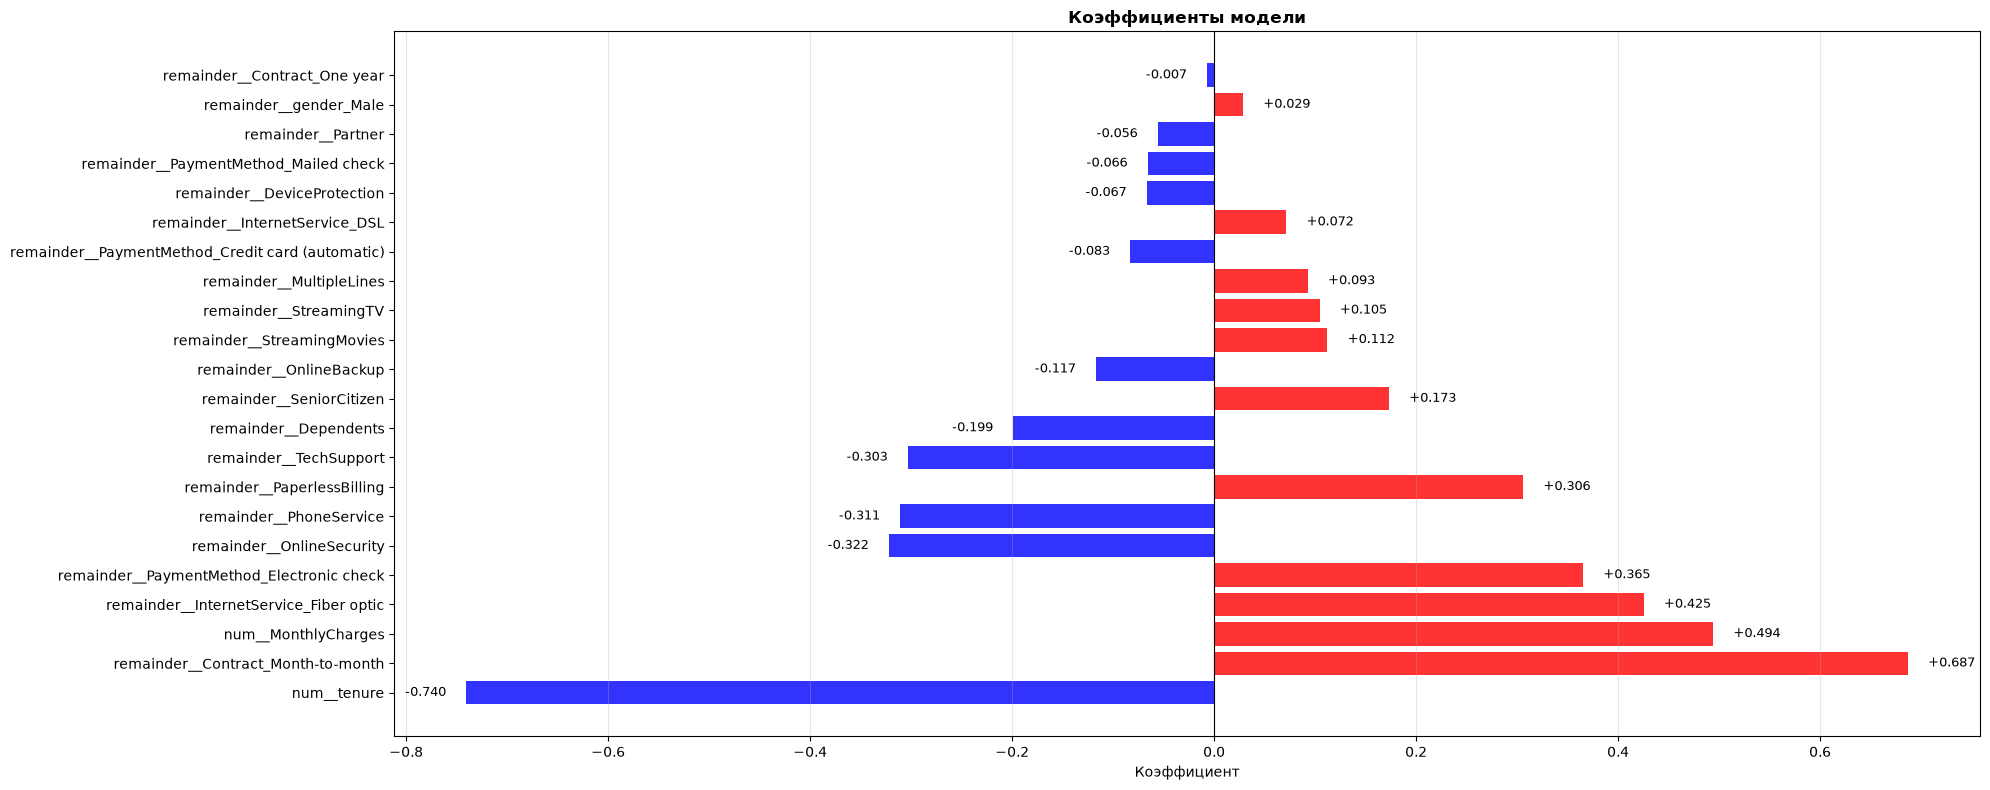

In [158]:
best_model_plain.fit(X_train, y_train_bin)

clf = best_model_plain.named_steps['classifier']
feature_names = best_model_plain.named_steps['preprocessor'].get_feature_names_out()
coef = clf.coef_[0]

coef_sorted = pd.DataFrame({
    'feature': feature_names,
    'coef': coef,
    'abs_coef': np.abs(coef),
}).sort_values('abs_coef', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(20, 8))
colors = ['red' if c > 0 else 'blue' for c in coef_sorted['coef']]
ax.barh(coef_sorted['feature'], coef_sorted['coef'], color=colors, alpha=0.8)
ax.axvline(0, color='black', linewidth=0.8)

for i, c in enumerate(coef_sorted['coef']):
    ax.text(c + (0.02 if c >= 0 else -0.02), i, f'{c:+.3f}',
            va='center', ha='left' if c >= 0 else 'right', fontsize=9)

ax.set_xlabel('Коэффициент')
ax.set_title('Коэффициенты модели', fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

* Факторы, увеличивающие риск оттока: самый сильный - договор с месячным сроком. Также повышают риск - услуга интернета с Fiber Optic, оплата электронным чеком и размер ежемесячного платежа.
* Факторы, снижающие риск оттока: общий срок обслуживания клиента, наличие услуги онлайн-безопасности, телефонной связи и технической поддержки.
* Влияние пола, наличие партнера или годового контракта минимально (0.05 по модулю и меньше) - их можно считать незначимыми для прогноза.

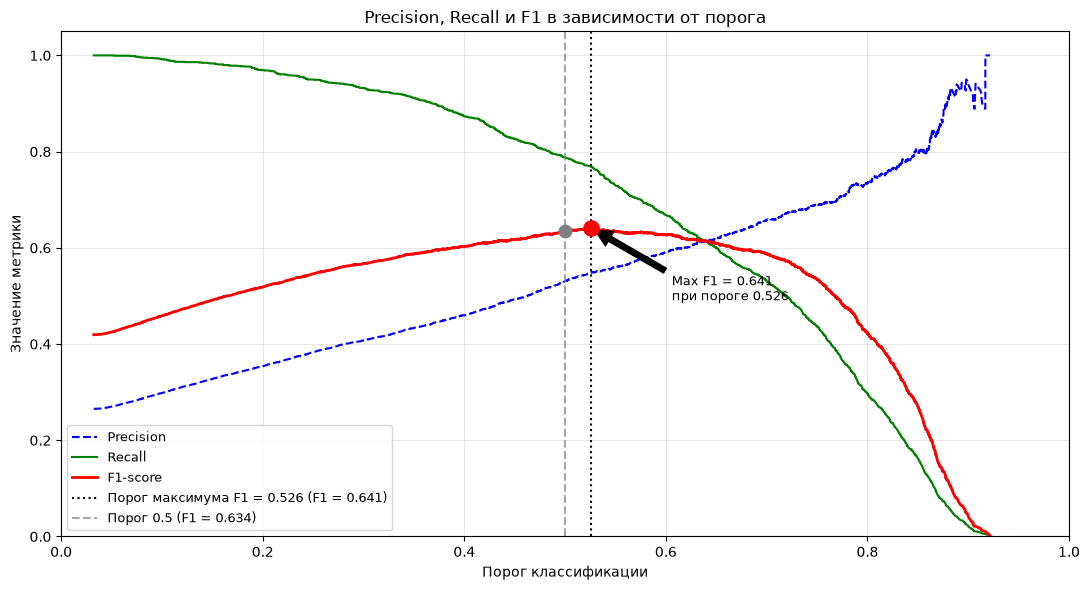

Максимальный F1 = 0.6410 при пороге = 0.5258
F1 при пороге 0.5 = 0.6342


In [159]:
y_proba_best = cross_val_predict(
    best_model_plain,
    X_train, y_train_bin,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train_bin, y_proba_best)

precision = precision[:-1]
recall = recall[:-1]
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

f1_05 = f1_score(y_train_bin, (y_proba_best >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(thresholds, precision, 'b--', label='Precision')
ax.plot(thresholds, recall, 'g-', label='Recall')
ax.plot(thresholds, f1_scores, 'r-', linewidth=2, label='F1-score')

ax.axvline(
    x=best_threshold, color='black', linestyle=':',
    label=f'Порог максимума F1 = {best_threshold:.3f} (F1 = {best_f1:.3f})'
)
ax.scatter(best_threshold, best_f1, color='red', s=120, zorder=5)
ax.annotate(
    f'Max F1 = {best_f1:.3f}\nпри пороге {best_threshold:.3f}',
    xy=(best_threshold, best_f1),
    xytext=(best_threshold + 0.08, best_f1 - 0.15),
    arrowprops=dict(facecolor='black', shrink=0.05),
    fontsize=9,
)

ax.axvline(
    x=0.5, color='gray', linestyle='--', alpha=0.7,
    label=f'Порог 0.5 (F1 = {f1_05:.3f})'
)
ax.scatter(0.5, f1_05, color='gray', s=80, zorder=5)

ax.set_xlabel('Порог классификации')
ax.set_ylabel('Значение метрики')
ax.set_title('Precision, Recall и F1 в зависимости от порога')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower left', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


print(f"Максимальный F1 = {best_f1:.4f} при пороге = {best_threshold:.4f}")
print(f"F1 при пороге 0.5 = {f1_05:.4f}")


При пороге 0.526 достигается максимальный `F1 = 0.641`. Метрика практически идентична стандартному порогу 0.5, где F1 = 0.634.  

Выбор порога можно смещать от 0.5 до 0.52, но поскольку мы предполагаем, что отток клиента дороже его удержания, то оптимальным будет - остановиться на трешхолде 0.5, т.к. с повышением порога F1 растет за счет снижения полносты и роста точности.

## **Основные выводы по результатам построения модели**


1) Финальная конфигурация модели: логистическая регрессия с L2-регуляризацией ((solver='lbfgs', C = 0.01), class_weight='balanced') и без полиномиальных признаков. Итоговое качество: `F1 = 0.634, ROC-AUC = 0.84` на кросс-валидации, что существенно превосходит Dummy-стратегию (F1=0.28, ROC-AUC=0.51).

2) Полиномиальные признаки не дают значимого прироста модели, но несут риск для дестабилизации коэффициентов. 

3) Модель устойчива и не переобучается: разрыв между train и CV практически нулевой (gap F1 = 0.0003), а кривая обучения выходит на плато при 2800-3000 наблюдениях. ТОП-10 комбинаций гиперпараметров различаются в пределах 0.001 по F1 - модель малочувствительна к точной настройке.

4) Оптимальный порог классификации `0.52 (F1 = 0.641)` практически совпадает с дефолтным 0.5. При этом модель смещена в сторону recall (0.79 при precision 0.53) - это оправданно для оттока, где пропустить ушедшего клиента дороже, чем ошибочно удержать.
 
5) После всех проведенных экспериментов можно сделать главный вывод - максимальное значение F1 для логистической регрессии достигнуто. Дальнейшего роста качества следует добиваться через использование других моделей (деревья, бустинги), а не в дообучении логрега.